# Redis and Caching for AI Applications

> **Who is this for:** learners who can write a small Python web service and now want to make it fast, cheap and safe under real traffic, especially an AI SaaS product that calls LLMs.
>
> **What you will learn:**
> - **caching from first principles**: why caches work (locality, Zipf traffic), hit-rate math and how it changes latency and LLM cost, and where caches live (browser, CDN, reverse proxy, in-process, distributed cache, database buffer pool)
> - **HTTP caching headers** (`Cache-Control`, `ETag`, `stale-while-revalidate`) and how they apply to AI APIs
> - **caching patterns**: cache-aside, read-through, write-through, write-behind, refresh-ahead; TTL choice and jitter; invalidation; cache stampede (single-flight, locks, XFetch); hot keys; negative caching; the classic DB-write vs cache-delete race; eviction policies (LRU, LFU, FIFO, random) compared under Zipf traffic
> - **Redis in depth**: the event loop and I/O threads, every major data type, persistence (RDB, AOF), replication, Sentinel, Redis Cluster (16384 hash slots, hash tags, with a CRC16 slot calculator), memory sizing, key design, pipelining, transactions, Lua/functions, client-side caching, security
> - **Redis for AI SaaS**: LLM response caching, semantic caching, chat-history store, four rate limiters compared, per-tenant quotas, job queues with Streams and dead letters, pub/sub for token streaming, leaderboards, feature flags, distributed locks, vector search in Redis
> - **operating it**: managed options on AWS, GCP, Azure, Upstash and Redis Cloud; Redis vs Valkey vs Dragonfly; monitoring; failure modes
>
> **Prerequisites:** [System Design Fundamentals](../23_Software_Engineering/09_system_design_fundamentals.ipynb) (has a short caching section), [NoSQL Databases](02_nosql/01_nosql_databases.ipynb) (first look at Redis). Helpful: [Distributed Systems and Architecture Patterns](../22_ML_System_Design/10_distributed_systems_and_architecture_patterns.ipynb) and [LLM Caching](../08_LLM/23_llm_caching_kv_cache_prompt_semantic_cag.ipynb).
>
> **Time needed:** about 2.5-3 hours to read and play. The notebook itself runs in well under a minute.
>
> **Runs on:** CPU, no API key, no internet, **no Redis server needed**. We build a small pure-Python "mini Redis" and use it for every demo. One optional cell at the end talks to a real Redis only if one is running on your machine. Every price in this notebook is **made-up and only for illustration**.

### How this notebook relates to the rest of the repo

| Topic | Covered in depth in | What this notebook adds |
|---|---|---|
| Cache basics, first look at rate limiting | [23_Software_Engineering/09](../23_Software_Engineering/09_system_design_fundamentals.ipynb) | patterns with runnable demos, stampede math, eviction comparison |
| Redis as a NoSQL store | [13_Databases/02_nosql/01](02_nosql/01_nosql_databases.ipynb), [22_ML_System_Design/04](../22_ML_System_Design/04_nosql_and_data_stores.ipynb) | internals, cluster, persistence, operations |
| Distributed locks, fencing tokens, Redlock debate | [22_ML_System_Design/10](../22_ML_System_Design/10_distributed_systems_and_architecture_patterns.ipynb) | the Redis commands for a lock, and a short reminder of the caveats |
| Cache stampede and CDN at very large scale | [22_ML_System_Design/12](../22_ML_System_Design/12_designing_for_100_million_users.ipynb) | the XFetch algorithm and single-flight, simulated |
| KV cache, prompt caching, semantic caching | [08_LLM/23](../08_LLM/23_llm_caching_kv_cache_prompt_semantic_cag.ipynb) | storing those caches in Redis, cache keys, tenant isolation |
| Indexes (B-tree, hash, HNSW) | [13_Databases/09](09_indexing_patterns_database_and_vector_side_by_side.ipynb) | how Redis indexes vectors, and when a separate vector DB is better |
| Message queues (Kafka, RabbitMQ) | [16_Deployment/message_queues](../16_Deployment/message_queues/01_message_queues.ipynb) | Redis lists and Streams as job queues |

## 0. Setup

We use only the Python standard library, numpy, pandas and matplotlib. We fix the random seed so you get the same numbers every time.

In [1]:
import hashlib, json, math, random, time, bisect, heapq, socket, os
from collections import OrderedDict, defaultdict, deque, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)
pd.set_option("display.width", 120)
print("setup ok")

setup ok


## 1. Caching from first principles

**What it is:** a **cache** is a small, fast store that keeps copies of data (or results) that are slow or expensive to get from the original source. The original source is called the **source of truth** or **backing store** (often a database, or an LLM API).

**Simple analogy:** you keep the five spices you use every day on the kitchen counter, and the other fifty in the cupboard in the basement. The counter is small, but most of the time what you need is already there.

**How it works:**
1. A request asks for a key (for example `user:42` or "the answer to this prompt").
2. Look in the cache. If it is there, that is a **hit**: return it.
3. If not, that is a **miss**: get it from the slow source, store a copy in the cache, return it.
4. Copies do not live forever: they **expire** (a **TTL**, time to live) or are **evicted** (thrown out to make room).

### 1.1 Why caches work: locality and Zipf traffic

Caches only help if the same things are asked for again. Two facts make this true in real systems:

- **Temporal locality:** something used recently is likely to be used again soon (a user who just opened a chat will send another message).
- **Spatial locality:** things stored near each other are used together (the next row, the next memory address). This matters more for CPU caches and database pages than for Redis.

Real traffic is also **skewed**. Most requests go to a few popular items. A common model for this is the **Zipf distribution**: the item with rank `r` is requested with probability proportional to `1 / r^s`. With `s` around 1, a tiny share of items gets a large share of the traffic. The cell below shows how much.

In [2]:
def zipf_probs(n_items, s=1.0):
    """Probability of each item rank 1..n under a Zipf law with exponent s."""
    ranks = np.arange(1, n_items + 1)
    weights = 1.0 / ranks**s
    return weights / weights.sum()

n_items = 100_000
rows = []
for s in [0.6, 0.8, 1.0, 1.2]:
    p = zipf_probs(n_items, s)
    cum = np.cumsum(p)
    rows.append({"zipf s": s,
                 "top 0.1% of keys": f"{cum[int(n_items*0.001)-1]:.0%}",
                 "top 1% of keys": f"{cum[int(n_items*0.01)-1]:.0%}",
                 "top 10% of keys": f"{cum[int(n_items*0.10)-1]:.0%}"})
print("Share of all requests that go to the most popular keys (100,000 keys):")
print(pd.DataFrame(rows).to_string(index=False))

Share of all requests that go to the most popular keys (100,000 keys):
 zipf s top 0.1% of keys top 1% of keys top 10% of keys
    0.6               6%            15%             39%
    0.8              18%            34%             60%
    1.0              43%            62%             81%
    1.2              71%            85%             94%


Read the table like this: with `s = 1.0`, caching only the top 1% of keys already serves a large share of all requests. That is why a cache that holds a small fraction of the data can still have a high hit rate. If your traffic is close to uniform (small `s`), caching helps much less.

### 1.2 Hit-rate math: latency and cost

Let `h` be the hit rate, `t_cache` the time to check the cache and `t_src` the time to get the data from the source on a miss. Then the average time per request is:

`average latency = t_cache + (1 - h) * t_src`

The same shape works for money: `average cost = (1 - h) * cost_per_miss` (cache cost is usually tiny by comparison). For an LLM API the source is slow (seconds) and expensive (tokens), so even a modest hit rate matters a lot. The miss rate `(1 - h)` is what you pay for: going from 90% to 99% hits cuts the misses by 10x.

The numbers below are **made-up and only for illustration**.

hit rate  avg latency ms  LLM calls/day  LLM cost/day ($, made-up)
      0%          2501.0        1000000                     4000.0
     20%          2001.0         800000                     3200.0
     50%          1251.0         500000                     2000.0
     80%           501.0         199999                      800.0
     90%           251.0          99999                      400.0
     95%           126.0          50000                      200.0
     99%            26.0          10000                       40.0


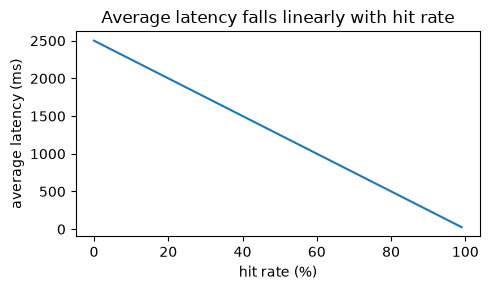

In [3]:
t_cache_ms = 1.0          # Redis round trip inside the same region (illustrative)
t_llm_ms = 2500.0         # an LLM call (illustrative)
cost_per_llm_call = 0.004 # dollars per call (made-up)
calls_per_day = 1_000_000

rows = []
for h in [0.0, 0.2, 0.5, 0.8, 0.9, 0.95, 0.99]:
    avg_ms = t_cache_ms + (1 - h) * t_llm_ms
    daily_cost = (1 - h) * calls_per_day * cost_per_llm_call
    rows.append({"hit rate": f"{h:.0%}", "avg latency ms": round(avg_ms, 1),
                 "LLM calls/day": int((1 - h) * calls_per_day),
                 "LLM cost/day ($, made-up)": round(daily_cost, 0)})
print(pd.DataFrame(rows).to_string(index=False))

hs = np.linspace(0, 0.99, 100)
plt.figure(figsize=(5, 3))
plt.plot(hs * 100, t_cache_ms + (1 - hs) * t_llm_ms)
plt.xlabel("hit rate (%)"); plt.ylabel("average latency (ms)")
plt.title("Average latency falls linearly with hit rate")
plt.tight_layout(); plt.show()

**Careful with averages.** The average improves, but the **p99** (the slowest 1% of requests) is still a miss as long as the miss rate is above 1%. Users who get a miss still wait the full LLM time. Caching makes the typical case fast; it does not remove the slow path.

### 1.3 Where caches live

A request from a user passes many layers, and each layer can cache. Closer to the user means faster but harder to invalidate and less private.

```mermaid
flowchart LR
    B["Browser cache<br/>(per user)"] --> CDN["CDN / edge cache<br/>(shared, many cities)"]
    CDN --> RP["Reverse proxy cache<br/>(nginx, Varnish, API gateway)"]
    RP --> APP["App server<br/>in-process cache (L1)<br/>dict, LRU, per process"]
    APP --> R["Distributed cache (L2)<br/>Redis / Valkey<br/>shared by all app servers"]
    R --> DB[("Database<br/>with its own buffer pool")]
    APP --> LLM["LLM API<br/>(provider prompt cache inside)"]
```

| Layer | What it usually stores | Typical lifetime | Shared by | Main risk |
|---|---|---|---|---|
| Browser | static files, some GET API responses | minutes to a year | one user | stale UI after a deploy |
| CDN / edge | images, JS, public pages, public API responses | seconds to days | everyone | caching private data by mistake |
| Reverse proxy | whole HTTP responses | seconds to minutes | everyone behind it | same as CDN |
| In-process (L1) | hot config, feature flags, tiny lookups | seconds | one process | each process has a different copy |
| Distributed (L2, Redis) | sessions, query results, LLM answers, counters | seconds to days | all app servers | network hop, a shared failure point |
| DB buffer pool | data pages in RAM | until evicted | the database | you do not control it directly |
| Provider prompt cache | the model's KV cache for a repeated prompt prefix | minutes | your account | see [08_LLM/23](../08_LLM/23_llm_caching_kv_cache_prompt_semantic_cag.ipynb) |

**Multi-level caching** means checking L1 first (nanoseconds), then L2 (about a millisecond), then the source. L1 takes the hottest keys off Redis; Redis takes most traffic off the database or LLM.

### 1.4 HTTP caching headers for AI APIs

**What it is:** HTTP has built-in rules (RFC 9111) that tell browsers, CDNs and proxies whether and how long they may keep a response.

| Header | Meaning in one sentence |
|---|---|
| `Cache-Control: max-age=60` | anyone may reuse this response for 60 seconds without asking again |
| `Cache-Control: s-maxage=300` | shared caches (CDN, proxy) may keep it for 300 seconds; overrides `max-age` for them |
| `Cache-Control: private` | only the user's own browser may cache it, never a shared cache |
| `Cache-Control: no-store` | nobody may store it at all (use for anything with personal data or secrets) |
| `Cache-Control: no-cache` | you may store it, but must check with the server (revalidate) before each reuse |
| `stale-while-revalidate=30` | after it expires, you may still serve the old copy for 30 more seconds while you fetch a fresh one in the background (RFC 5861) |
| `ETag: "abc123"` | a version tag for the response body; the client sends `If-None-Match: "abc123"` next time and the server answers `304 Not Modified` (no body) if nothing changed |
| `Vary: Authorization` | the cache must keep separate copies per value of this request header |

**For AI APIs:**
- A chat completion for a logged-in user is personal: `Cache-Control: private, no-store`. Cache it (if at all) in **your** Redis, keyed by tenant, not in a CDN.
- Public, slowly changing outputs (a model list, a public "summary of today's docs", embeddings of public text) can use `s-maxage` plus `stale-while-revalidate`.
- Streaming responses (server-sent events) are not cached by HTTP caches in a useful way.

The small function below decides what a cache should do with a stored response. It is a toy version of the RFC rules.

In [4]:
def http_cache_decision(cache_control: str, age_s: float, etag_matches: bool | None = None):
    """Toy decision: what should a shared cache do with a stored response of a given age?"""
    cc = {}
    for part in cache_control.replace(" ", "").split(","):
        k, _, v = part.partition("=")
        cc[k.lower()] = int(v) if v.isdigit() else True
    if "no-store" in cc or "private" in cc:
        return "do not store in a shared cache; always go to origin"
    max_age = cc.get("s-maxage", cc.get("max-age", 0))
    if "no-cache" in cc:
        max_age = 0
    if age_s <= max_age:
        return "FRESH: serve from cache"
    swr = cc.get("stale-while-revalidate", 0)
    if age_s <= max_age + swr:
        return "STALE but allowed: serve old copy now, refresh in background"
    if etag_matches:
        return "REVALIDATE: send If-None-Match, origin says 304, reuse body"
    return "EXPIRED: fetch a full new response from origin"

cases = [("public, s-maxage=60, stale-while-revalidate=30", 10, None),
         ("public, s-maxage=60, stale-while-revalidate=30", 75, None),
         ("public, s-maxage=60, stale-while-revalidate=30", 200, True),
         ("public, s-maxage=60", 200, False),
         ("private, no-store", 1, None),
         ("no-cache", 1, True)]
for cc, age, et in cases:
    print(f"{cc:<50} age={age:>4}s -> {http_cache_decision(cc, age, et)}")

public, s-maxage=60, stale-while-revalidate=30     age=  10s -> FRESH: serve from cache
public, s-maxage=60, stale-while-revalidate=30     age=  75s -> STALE but allowed: serve old copy now, refresh in background
public, s-maxage=60, stale-while-revalidate=30     age= 200s -> REVALIDATE: send If-None-Match, origin says 304, reuse body
public, s-maxage=60                                age= 200s -> EXPIRED: fetch a full new response from origin
private, no-store                                  age=   1s -> do not store in a shared cache; always go to origin
no-cache                                           age=   1s -> REVALIDATE: send If-None-Match, origin says 304, reuse body


In [5]:
# ETag in practice: hash the response body, answer 304 when the client already has it.
def make_etag(body: dict) -> str:
    return '"' + hashlib.sha256(json.dumps(body, sort_keys=True).encode()).hexdigest()[:16] + '"'

models_list = {"models": ["small-chat-v3", "embed-v2"], "updated": "2026-11-01"}
server_etag = make_etag(models_list)

def handle_get_models(if_none_match=None):
    if if_none_match == server_etag:
        return 304, {"ETag": server_etag}, None                # no body sent
    return 200, {"ETag": server_etag, "Cache-Control": "public, max-age=300"}, models_list

status, headers, body = handle_get_models()
print("first call :", status, headers, "body bytes =", len(json.dumps(body)))
status, headers, body = handle_get_models(if_none_match=headers["ETag"])
print("second call:", status, headers, "body =", body)

first call : 200 {'ETag': '"c7a48c22ebbe101e"', 'Cache-Control': 'public, max-age=300'} body bytes = 66
second call: 304 {'ETag': '"c7a48c22ebbe101e"'} body = None


## 2. Caching patterns, with runnable demos

To make the demos honest we need a slow source of truth that counts how often it is hit. `FakeDB` below is a plain dict with a counter and a pretend latency. In this section the cache is a tiny dict-with-TTL; from section 3 on we use the mini Redis.

We also use a **fake clock** so TTL demos are instant and repeatable: `clock.advance(10)` moves time forward 10 seconds without waiting.

In [6]:
class FakeClock:
    """A clock we control by hand, so expiry demos run instantly and repeatably."""
    def __init__(self, start=1_000_000.0):
        self.t = start
    def __call__(self):
        return self.t
    def advance(self, seconds):
        self.t += seconds

class FakeDB:
    """Stand-in for a slow database (or an LLM API): counts reads and writes."""
    def __init__(self, data=None, read_ms=20.0):
        self.data = dict(data or {})
        self.reads = 0
        self.writes = 0
        self.read_ms = read_ms
    def read(self, key):
        self.reads += 1
        return self.data.get(key)
    def write(self, key, value):
        self.writes += 1
        self.data[key] = value

class TTLCache:
    """A minimal dict cache with per-key expiry (used only in section 2)."""
    def __init__(self, clock):
        self.clock, self.store = clock, {}
        self.hits = self.misses = 0
    def get(self, key):
        item = self.store.get(key)
        if item is None or item[1] <= self.clock():
            self.store.pop(key, None)
            self.misses += 1
            return None
        self.hits += 1
        return item[0]
    def set(self, key, value, ttl):
        self.store[key] = (value, self.clock() + ttl)
    def delete(self, key):
        self.store.pop(key, None)
    def ttl(self, key):
        item = self.store.get(key)
        return None if item is None else item[1] - self.clock()

print("helpers ready")

helpers ready


### 2.1 The five classic patterns

```mermaid
flowchart TB
    subgraph CA["Cache-aside (lazy loading)"]
        A1[App] -->|1 get| C1[(Cache)]
        A1 -->|2 on miss: read| D1[(DB)]
        A1 -->|3 set| C1
    end
    subgraph RT["Read-through"]
        A2[App] -->|get| C2[(Cache + loader)]
        C2 -->|on miss the cache itself loads| D2[(DB)]
    end
    subgraph WT["Write-through"]
        A3[App] -->|write| C3[(Cache)]
        C3 -->|same request, synchronously| D3[(DB)]
    end
    subgraph WB["Write-behind (write-back)"]
        A4[App] -->|write| C4[(Cache)]
        C4 -.->|later, in batches| D4[(DB)]
    end
```

| Pattern | What it is | Good for | Watch out for |
|---|---|---|---|
| **Cache-aside** | the app checks the cache, and on a miss reads the DB and fills the cache | most read-heavy apps; the default with Redis | first request is always slow; stale data until TTL or delete |
| **Read-through** | the app only talks to the cache; the cache library knows how to load misses | cleaner app code (a "loading cache" library) | same staleness as cache-aside |
| **Write-through** | every write goes to the cache and the DB in the same request | data read right after it is written | writes get slower; cache fills with data nobody reads |
| **Write-behind** | writes go to the cache and are flushed to the DB later, in batches | very high write rates, counters, analytics | data loss if the cache dies before the flush |
| **Refresh-ahead** | popular keys are reloaded shortly **before** they expire | hot keys where a miss is very expensive (LLM answers) | wasted reloads for keys that would not be read again |

In [7]:
clock = FakeClock()
db = FakeDB({f"user:{i}": {"id": i, "plan": "free"} for i in range(100)})
cache = TTLCache(clock)

# --- Cache-aside: the application does the work ---
def get_user_cache_aside(key, ttl=60):
    value = cache.get(key)
    if value is not None:
        return value
    value = db.read(key)
    if value is not None:
        cache.set(key, value, ttl)
    return value

keys = [f"user:{np.random.zipf(1.3) % 100}" for _ in range(2000)]
for k in keys:
    get_user_cache_aside(k)
    clock.advance(0.05)                    # 2000 requests over 100 seconds
total = cache.hits + cache.misses
print(f"cache-aside: {total} requests, hit rate {cache.hits/total:.1%}, DB reads {db.reads}")

cache-aside: 2000 requests, hit rate 91.0%, DB reads 181


In [8]:
# --- Read-through: the cache owns a loader function ---
class ReadThroughCache(TTLCache):
    def __init__(self, clock, loader, ttl):
        super().__init__(clock)
        self.loader, self.default_ttl = loader, ttl
    def get(self, key):
        value = super().get(key)
        if value is None:
            value = self.loader(key)                 # the cache calls the DB, not the app
            if value is not None:
                self.set(key, value, self.default_ttl)
        return value

clock = FakeClock(); db = FakeDB({"price:gpu": 2.5})
rt = ReadThroughCache(clock, loader=db.read, ttl=30)
print([rt.get("price:gpu") for _ in range(5)], "DB reads:", db.reads)

# --- Write-through: write both, synchronously ---
def update_price_write_through(key, value):
    db.write(key, value)          # write the source of truth first
    rt.set(key, value, 30)        # then the cache, in the same request
update_price_write_through("price:gpu", 2.1)
print("after write-through, cache gives", rt.get("price:gpu"), "| DB writes:", db.writes, "DB reads:", db.reads)

[2.5, 2.5, 2.5, 2.5, 2.5] DB reads: 1
after write-through, cache gives 2.1 | DB writes: 1 DB reads: 1


In [9]:
# --- Write-behind: buffer writes, flush in batches ---
class WriteBehindCounter:
    """Usage counters: increments hit the cache immediately, the DB only on flush."""
    def __init__(self, db, flush_every=100):
        self.db, self.flush_every = db, flush_every
        self.pending = Counter()
        self.ops = 0
    def incr(self, key, n=1):
        self.pending[key] += n
        self.ops += 1
        if self.ops % self.flush_every == 0:
            self.flush()
    def flush(self):
        for key, n in self.pending.items():
            self.db.write(key, (self.db.data.get(key) or 0) + n)
        self.pending.clear()

db = FakeDB()
wb = WriteBehindCounter(db, flush_every=100)
for i in range(1000):
    wb.incr(f"tokens:tenant-{i % 3}", 50)
wb.flush()
print("1000 increments ->", db.writes, "DB writes. Totals:", db.data)
print("Risk: if the process dies between flushes, up to", wb.flush_every, "increments are lost.")

1000 increments -> 30 DB writes. Totals: {'tokens:tenant-0': 16700, 'tokens:tenant-1': 16650, 'tokens:tenant-2': 16650}
Risk: if the process dies between flushes, up to 100 increments are lost.


In [10]:
# --- Refresh-ahead: reload a hot key when little TTL is left ---
clock = FakeClock(); db = FakeDB({"faq:pricing": "v1"}); cache = TTLCache(clock)
REFRESH_WHEN_LEFT = 10   # seconds

def get_refresh_ahead(key, ttl=60):
    value = cache.get(key)
    left = cache.ttl(key)
    if value is None:
        value = db.read(key); cache.set(key, value, ttl)          # normal miss
    elif left is not None and left < REFRESH_WHEN_LEFT:
        # In real code this runs in the background; the user still gets the cached value now.
        cache.set(key, db.read(key), ttl)
    return value

misses_seen_by_users = 0
for second in range(0, 300):
    before = cache.misses
    get_refresh_ahead("faq:pricing")
    misses_seen_by_users += cache.misses - before
    clock.advance(1)
print(f"300 reads over 300 s: user-visible misses = {misses_seen_by_users}, DB reads = {db.reads}")
print("Without refresh-ahead there would be one user-visible miss every 60 s (about 5).")

300 reads over 300 s: user-visible misses = 1, DB reads = 6
Without refresh-ahead there would be one user-visible miss every 60 s (about 5).


### 2.2 Choosing a TTL, and adding jitter

**TTL** (time to live) is how long a cached copy is allowed to exist. Rules of thumb:

| Data | Typical TTL idea | Why |
|---|---|---|
| user session | 30 min sliding (reset on each use) | security; idle users log out |
| feature flags, config | 10-60 s | changes must spread quickly |
| product catalog, model list | minutes to an hour | changes rarely, and you also delete on write |
| LLM answer for a fixed prompt | hours to days, plus a version in the key | expensive to recompute; invalidate by bumping the version |
| "not found" results | a few seconds to a minute | a new record may appear soon |

**Jitter:** if you load 10,000 keys at the same moment with the same TTL, they all expire at the same moment and the database gets 10,000 misses at once. Adding a small random amount to each TTL (for example plus or minus 10%) spreads the expiries out.

In [11]:
n_keys, base_ttl = 10_000, 3600
no_jitter = np.full(n_keys, base_ttl)
with_jitter = base_ttl + np.random.uniform(-0.1, 0.1, n_keys) * base_ttl

def worst_second(expiry_times):
    return Counter(np.floor(expiry_times).astype(int)).most_common(1)[0][1]

print("keys expiring in the busiest single second")
print("  no jitter  :", worst_second(no_jitter))
print("  +/-10% jitter:", worst_second(with_jitter))

keys expiring in the busiest single second
  no jitter  : 10000
  +/-10% jitter: 26


### 2.3 Invalidation strategies

"There are only two hard things in computer science: cache invalidation and naming things" (a saying usually credited to Phil Karlton). **Invalidation** means removing or replacing a cached copy when the source changes.

| Strategy | How | Pros | Cons |
|---|---|---|---|
| **TTL only** | do nothing; wait for expiry | simplest | stale for up to one TTL |
| **Delete on write** | after updating the DB, `DEL` the cache key | fresh soon after writes | race conditions (see 2.6); must know every key that depends on the row |
| **Versioned keys** | put a version number in the key; bump the version to "invalidate" everything at once | invalidates thousands of keys in one step; no scan needed | old keys linger until TTL (memory) |
| **Event-driven** | the writer publishes an "X changed" event; every cache holder deletes its copy | works for many in-process L1 caches | events can be lost; needs a bus (pub/sub, Kafka, CDC) |

The cell shows versioned keys: when a tenant edits its system prompt, every cached answer built with the old prompt must stop being used. Deleting them one by one is slow; bumping a version number is instant.

In [12]:
clock = FakeClock(); cache = TTLCache(clock)
versions = {"tenant-a": 1}      # in real life this counter also lives in Redis (INCR)

def answer_key(tenant, question):
    v = versions[tenant]
    qh = hashlib.sha256(question.encode()).hexdigest()[:12]
    return f"ans:v{v}:{tenant}:{qh}"

cache.set(answer_key("tenant-a", "What is your refund policy?"), "30 days (old prompt)", 3600)
print("before edit :", cache.get(answer_key("tenant-a", "What is your refund policy?")))

versions["tenant-a"] += 1        # tenant edits the system prompt -> one increment
print("after edit  :", cache.get(answer_key("tenant-a", "What is your refund policy?")),
      "(miss, so the answer is regenerated with the new prompt)")

before edit : 30 days (old prompt)
after edit  : None (miss, so the answer is regenerated with the new prompt)


In [13]:
# Event-driven invalidation of in-process (L1) caches on three app servers.
class Bus:
    """A tiny in-process message bus (Redis pub/sub plays this role in production)."""
    def __init__(self): self.subs = []
    def subscribe(self, fn): self.subs.append(fn)
    def publish(self, msg):
        for fn in self.subs: fn(msg)

bus = Bus()
servers = {name: {} for name in ["app-1", "app-2", "app-3"]}
for name, l1 in servers.items():
    bus.subscribe(lambda msg, l1=l1: l1.pop(msg["key"], None))

for l1 in servers.values():
    l1["flags:tenant-a"] = {"new_ui": False}
print("before:", {n: l1.get("flags:tenant-a") for n, l1 in servers.items()})
bus.publish({"event": "changed", "key": "flags:tenant-a"})     # writer updates DB, then publishes
print("after :", {n: l1.get("flags:tenant-a") for n, l1 in servers.items()})

before: {'app-1': {'new_ui': False}, 'app-2': {'new_ui': False}, 'app-3': {'new_ui': False}}
after : {'app-1': None, 'app-2': None, 'app-3': None}


### 2.4 Cache stampede (thundering herd on one key)

**What it is:** a popular key expires, and hundreds of requests miss at the same time. All of them run the expensive recompute (a big SQL query, an LLM call) in parallel. The source gets overloaded exactly when it is needed most. [22_ML_System_Design/12](../22_ML_System_Design/12_designing_for_100_million_users.ipynb) shows this at scale; here we compare three fixes in a small simulation.

**Simple analogy:** the coffee pot runs out, and instead of one person making a new pot, twenty people each start making one.

| Fix | How it works | Trade-off |
|---|---|---|
| **Single-flight / request coalescing** | inside one process, only the first miss recomputes; the others wait for its result | only protects one process |
| **Lock (mutex) in Redis** | the first miss takes `SET lock:key token NX PX 5000`; others wait briefly or serve the stale value | needs a stale copy or a short wait; lock may expire early |
| **Probabilistic early expiry (XFetch)** | each reader may decide to recompute a little before expiry, with a probability that grows as expiry gets closer | no coordination at all; a few extra recomputes |
| **Refresh-ahead / never expire hot keys** | a background job keeps hot keys fresh | needs to know which keys are hot |

**XFetch** (Vattani, Chierichetti and Lowenstein, "Optimal Probabilistic Cache Stampede Prevention", VLDB 2015): store with the value the time `delta` it took to compute. On each read, recompute early if

`now - delta * beta * ln(random()) >= expiry`

Since `ln(random())` is negative, the left side is "now plus a random head start". `beta = 1` is the recommended default; a bigger `beta` recomputes earlier.

In [14]:
def simulate_stampede(strategy, n_seconds=600, req_per_s=200, ttl=60, recompute_s=2.0, beta=1.0, seed=0):
    """Discrete simulation of one hot key. Returns how many recomputes started and
    the largest number running at the same time (load spike on the source)."""
    rng = random.Random(seed)
    expiry = 0.0              # key starts missing
    delta = recompute_s
    in_flight = []            # finish times of recomputes currently running
    lock_until = 0.0
    recomputes, peak = 0, 0
    dt = 1.0 / req_per_s
    t = 0.0
    while t < n_seconds:
        # finish recomputes whose time is up: they refresh the key
        done = [f for f in in_flight if f <= t]
        if done:
            expiry = max(done) + ttl
            in_flight = [f for f in in_flight if f > t]
        has_value = t < expiry
        start = False
        if strategy == "none":
            start = not has_value
        elif strategy == "lock":
            if not has_value and t >= lock_until:     # SET NX succeeds for the first one only
                start, lock_until = True, t + recompute_s + 0.5
        elif strategy == "xfetch":
            if not has_value:
                start = not in_flight                 # cold start: one loader (single-flight)
            else:
                early = t - delta * beta * math.log(rng.random()) >= expiry
                start = early and not in_flight
        if start:
            recomputes += 1
            in_flight.append(t + recompute_s)
        peak = max(peak, len(in_flight))
        t += dt
    return recomputes, peak

rows = []
for s in ["none", "lock", "xfetch"]:
    r, p = simulate_stampede(s)
    rows.append({"strategy": s, "recomputes in 10 min": r, "peak concurrent recomputes": p})
print(pd.DataFrame(rows).to_string(index=False))
print("\nWith no protection, every request during the 2 s recompute window starts its own recompute.")

strategy  recomputes in 10 min  peak concurrent recomputes
    none                  4010                         401
    lock                    10                           1
  xfetch                    13                           1

With no protection, every request during the 2 s recompute window starts its own recompute.


Notice that with `lock` and `xfetch` the source sees exactly one recompute at a time. XFetch also avoids the moment where the key is missing at all, because it usually refreshes just before expiry, so users never see the slow path. In real code, single-flight inside each process plus XFetch or a Redis lock across processes is a strong combination.

### 2.5 Hot keys and negative caching

**Hot key:** one key that gets a huge share of traffic (a viral shared chat, the global "model list", a big tenant's config). In a cluster, one key lives on one shard, so that shard's CPU or network becomes the bottleneck while the others are idle.

Fixes:
1. **L1 in-process cache** with a very short TTL (1-5 s) in front of Redis: most reads never leave the app server.
2. **Key replicas:** write the value to `key#0 ... key#N-1` (different shards) and read a random one. Writes get N times more expensive.
3. **Read from replicas** for that key (if slightly stale reads are OK).
4. Find them: Redis has `redis-cli --hotkeys` (needs an LFU eviction policy), and Redis 8.6 added a `HOTKEYS` command.

**Negative caching:** cache the fact that something does **not** exist. Example: bots hammer `/v1/chat` with random invalid API keys; each one causes a DB lookup that finds nothing. Cache "not found" with a short TTL so repeated bad keys are cheap.

In [15]:
clock = FakeClock()
db = FakeDB({f"apikey:{i}": {"tenant": f"t{i}"} for i in range(10)})
cache = TTLCache(clock)
NOT_FOUND = "__none__"            # a sentinel value meaning "we checked: it does not exist"

def lookup_api_key(key, negative_cache=True):
    v = cache.get(key)
    if v is not None:
        return None if v == NOT_FOUND else v
    v = db.read(key)
    if v is not None:
        cache.set(key, v, 300)
    elif negative_cache:
        cache.set(key, NOT_FOUND, 30)     # short TTL: the key might be created soon
    return v

bad_keys = [f"apikey:bogus{random.randint(0, 20)}" for _ in range(5000)]   # bots retry the same few
for neg in [False, True]:
    db.reads = 0; cache.store.clear()
    for k in bad_keys:
        lookup_api_key(k, negative_cache=neg); clock.advance(0.01)
    print(f"negative caching={neg!s:<5} -> DB reads for 5000 invalid lookups: {db.reads}")

negative caching=False -> DB reads for 5000 invalid lookups: 5000
negative caching=True  -> DB reads for 5000 invalid lookups: 42


### 2.6 A consistency pitfall: the DB-write vs cache-delete race

Cache-aside with delete-on-write looks safe, but there is a known race. Two requests run at the same time:

```mermaid
sequenceDiagram
    participant R as Reader
    participant C as Cache
    participant D as DB
    participant W as Writer
    R->>C: GET plan (miss)
    R->>D: read plan = "free"
    W->>D: UPDATE plan = "pro"
    W->>C: DEL plan
    R->>C: SET plan = "free"   (old value!)
    Note over C: cache now says "free" until the TTL ends
```

The reader read the old value **before** the write, but wrote it into the cache **after** the delete. The cell replays exactly this order of steps.

In [16]:
def run_race(fix=None):
    db = {"user:7:plan": ("free", 1)}           # value, version
    cache = {}
    # Step 1: reader misses and reads the DB (old value, version 1)
    reader_value, reader_version = db["user:7:plan"]
    # Step 2: writer updates the DB and invalidates the cache key
    db["user:7:plan"] = ("pro", 2)
    if fix == "version-check":
        # instead of deleting, leave a short-lived "tombstone" that remembers the new version
        cache["user:7:plan"] = ("<empty>", 2)
    else:
        cache.pop("user:7:plan", None)
    # Step 3: reader, slightly late, fills the cache with what it read
    if fix == "version-check":
        # set-if-newer: only write if the cache does not already know a newer version
        # (in Redis: a small Lua script or function makes this check-and-set atomic)
        current = cache.get("user:7:plan")
        if current is None or current[1] < reader_version:
            cache["user:7:plan"] = (reader_value, reader_version)
    else:
        cache["user:7:plan"] = (reader_value, reader_version)
    if fix == "delayed-double-delete":
        # Step 4: writer deletes again after a short delay (longer than a typical read)
        cache.pop("user:7:plan", None)
    return db["user:7:plan"][0], cache.get("user:7:plan", ("<empty>",))[0]

for fix in [None, "delayed-double-delete", "version-check"]:
    db_val, cache_val = run_race(fix)
    status = "STALE" if cache_val not in ("<empty>", db_val) else "ok"
    print(f"fix={str(fix):<22} DB={db_val:<5} cache={cache_val:<8} -> {status}")

fix=None                   DB=pro   cache=free     -> STALE
fix=delayed-double-delete  DB=pro   cache=<empty>  -> ok
fix=version-check          DB=pro   cache=<empty>  -> ok


Practical defenses, from simplest to strongest:
1. **Always set a TTL**, so any stale entry heals itself.
2. **Delayed double delete:** delete, then delete again after a short delay.
3. **Versioned values:** store a version with the value and refuse to overwrite a newer version.
4. **Change data capture (CDC):** a process reads the database's change log (for example with Debezium) and deletes cache keys in commit order. The app never deletes keys itself.

If a stale value would be harmful (account balance, permissions, quota left), do not serve it from a cache at all, or keep the cache as a hint and check the source of truth for the final decision.

### 2.7 Eviction policies under Zipf traffic

When the cache is full, it must throw something out. The **eviction policy** decides what.

| Policy | Throws out | Good when | Weak when |
|---|---|---|---|
| **LRU** (least recently used) | the item not used for the longest time | recent items are likely to come back | a one-time scan of many keys pushes out the hot ones |
| **LFU** (least frequently used) | the item used the fewest times | popularity is stable (Zipf) | old popular items stay forever unless counts decay |
| **FIFO** | the oldest inserted item | simple, cheap | ignores popularity |
| **Random** | a random item | very cheap; surprisingly OK | no intelligence |
| **TTL-based** (`volatile-ttl` in Redis) | the item closest to expiry | TTLs reflect value | keys without TTL are never chosen |

Redis does not keep an exact LRU list (that costs memory). It samples a few keys (`maxmemory-samples`, default 5) and evicts the best candidate among them. Its LFU uses a small logarithmic counter that decays over time. The simulation below uses exact versions to compare the ideas.

In [17]:
def simulate_eviction(policy, requests, capacity, seed=0):
    rng = random.Random(seed)
    hits = 0
    if policy == "LRU":
        c = OrderedDict()
        for k in requests:
            if k in c: hits += 1; c.move_to_end(k)
            else:
                c[k] = 1
                if len(c) > capacity: c.popitem(last=False)
    elif policy == "FIFO":
        c, order = set(), deque()
        for k in requests:
            if k in c: hits += 1
            else:
                c.add(k); order.append(k)
                if len(c) > capacity: c.discard(order.popleft())
    elif policy == "Random":
        c, keys = {}, []
        for k in requests:
            if k in c: hits += 1
            else:
                if len(keys) >= capacity:
                    i = rng.randrange(len(keys)); old = keys[i]
                    keys[i] = keys[-1]; c[keys[i]] = i; keys.pop(); del c[old]
                c[k] = len(keys); keys.append(k)
    elif policy == "LFU":
        freq, c, heap = Counter(), set(), []
        for t, k in enumerate(requests):
            freq[k] += 1
            if k in c:
                hits += 1
            else:
                c.add(k)
                if len(c) > capacity:
                    while True:       # lazy heap: skip outdated entries
                        f, _, old = heapq.heappop(heap)
                        if old in c and freq[old] == f and old != k:
                            c.discard(old); break
            heapq.heappush(heap, (freq[k], t, k))
    return hits / len(requests)

n_keys, n_req = 20_000, 100_000
p = zipf_probs(n_keys, s=0.9)
reqs = np.random.choice(n_keys, size=n_req, p=p).tolist()

rows = []
for cap in [100, 500, 2000]:
    row = {"cache size (keys)": cap, "% of all keys": f"{cap/n_keys:.1%}"}
    for pol in ["LRU", "LFU", "FIFO", "Random"]:
        row[pol] = f"{simulate_eviction(pol, reqs, cap):.1%}"
    rows.append(row)
print("Hit rate under Zipf(s=0.9) traffic, 20,000 keys, 100,000 requests")
print(pd.DataFrame(rows).to_string(index=False))

Hit rate under Zipf(s=0.9) traffic, 20,000 keys, 100,000 requests
 cache size (keys) % of all keys   LRU   LFU  FIFO Random
               100          0.5% 22.2% 36.4% 19.0%  19.1%
               500          2.5% 38.9% 50.9% 34.9%  34.8%
              2000         10.0% 56.8% 64.5% 52.5%  52.9%


Typical result: LFU does best on stable Zipf traffic because it remembers popularity; LRU is close behind; FIFO and Random trail. Real traffic also changes over time (yesterday's viral chat is cold today), which is why Redis's LFU decays its counters and why `allkeys-lru` is a fine default. If you are unsure, start with `allkeys-lru` for a pure cache and `allkeys-lfu` if a few keys are always hot.

## 3. Redis in depth

### 3.1 What Redis is

**What it is:** Redis is an **in-memory data structure server**. Your app connects over TCP and sends small commands like `SET`, `GET`, `INCR`, `LPUSH`, `ZADD`. The data lives in RAM, so most commands finish in microseconds, and the values are not just strings but lists, hashes, sets, sorted sets, streams and more.

**Simple analogy:** a very fast shared whiteboard in the middle of the office. Every app server can write on it and read from it, and it has special areas for lists, scoreboards and to-do queues, not just sticky notes.

**Names you will see (as of late 2026):**
- **Redis Open Source** is the free server from Redis Ltd. (called "Redis Community Edition" for a short time in 2024; "Redis Stack" was the bundle with modules). Since **Redis 8** (May 2025) the old modules (JSON, time series, probabilistic types, the Query Engine for search and vectors) are built in, and there is a new **vector set** type.
- **Valkey** is a fork of Redis 7.2.4 run by the **Linux Foundation** since March 2024, with the same protocol and commands. Most cloud providers now offer it (see section 5).
- Licensing in one line each: Redis up to 7.2 was BSD-licensed; Redis 7.4 (March 2024) moved to a source-available dual licence (RSALv2 / SSPLv1); Redis 8 (May 2025) added **AGPLv3** as a third option, so it is open source again. Valkey stays BSD-licensed.

**How it works (the event loop):**

```mermaid
flowchart LR
    C1[client 1] --> IO
    C2[client 2] --> IO
    C3[client N] --> IO
    IO["I/O threads (optional)<br/>read sockets, parse commands,<br/>write replies"] --> Q["main thread<br/>runs ONE command at a time<br/>on the in-memory data"]
    Q --> IO
    Q -.-> BG["background threads / fork<br/>RDB snapshot, AOF rewrite,<br/>lazy free of big keys"]
```

- One **main thread** runs commands one after another. Because only one command runs at a time, every single command is **atomic**: `INCR` never loses an update, without any locks.
- An **event loop** (epoll on Linux) lets that one thread serve tens of thousands of connections: it only works on sockets that have data ready.
- **I/O threads** (`io-threads` setting; Redis 6 added them and Redis 8 reworked them) take over reading, parsing and writing on the network, which is often the real bottleneck. Command execution is still single-threaded. Valkey 8 has its own multithreaded I/O design.
- The flip side: one slow command (`KEYS *` on millions of keys, `HGETALL` on a huge hash, a long Lua script) blocks **everyone**. Rule: keep each command small.

### 3.2 Building a mini Redis in Python

To learn the commands without installing anything, we write `MiniRedis`, a single-process imitation. It is **not** Redis: it has no network, no persistence, and it is far slower. But the commands behave like the real ones for the parts we need, so every later demo reads like real Redis code (method names follow `redis-py`).

What it supports:
- strings: `get`, `set(ex=, px=, nx=, xx=)`, `incr`, `incrby`, `delete`, `exists`, `expire`, `ttl`, `persist`, `keys`
- hashes: `hset`, `hget`, `hgetall`, `hincrby`, `hdel`
- lists: `lpush`, `rpush`, `lpop`, `rpop`, `lrange`, `ltrim`, `llen`, `lmove`
- sets: `sadd`, `smembers`, `sismember`, `scard`
- sorted sets: `zadd`, `zincrby`, `zrange(withscores=, desc=)`, `zrangebyscore`, `zremrangebyscore`, `zcard`, `zscore`
- streams with consumer groups: `xadd`, `xgroup_create`, `xreadgroup`, `xack`, `xpending`, `xautoclaim`
- pub/sub (in-process): `publish`, `subscribe`
- transactions: `pipeline(transaction=True)` with `watch` (optimistic locking)
- `maxmemory` with eviction policies `noeviction`, `allkeys-lru`, `volatile-lru`, plus `info()` statistics

In [18]:
class WatchError(Exception):
    """Raised when a WATCHed key changed before EXEC (same name as in redis-py)."""

class OOMError(Exception):
    """Raised on writes when maxmemory is reached and the policy is noeviction."""

class MiniRedis:
    """A tiny, single-process imitation of Redis for learning. Not thread-safe, no network."""

    def __init__(self, clock=time.time, maxmemory=None, policy="noeviction"):
        self.clock = clock
        self.data = OrderedDict()   # key -> value; order = recency (for LRU)
        self.types = {}             # key -> "string" | "hash" | "list" | "set" | "zset" | "stream"
        self.expires = {}           # key -> absolute expiry time (seconds)
        self.version = Counter()    # key -> change counter (used by WATCH)
        self.maxmemory, self.policy = maxmemory, policy
        self.channels = defaultdict(list)
        self.stats = Counter()

    # ---------- internal helpers ----------
    def _alive(self, key):
        """Lazy expiry: a key past its TTL is deleted the moment someone touches it."""
        exp = self.expires.get(key)
        if exp is not None and exp <= self.clock():
            self._remove(key); self.stats["expired_keys"] += 1
            return False
        return key in self.data

    def _remove(self, key):
        self.data.pop(key, None); self.types.pop(key, None); self.expires.pop(key, None)
        self.version[key] += 1

    def _touch(self, key):
        self.data.move_to_end(key)          # mark as most recently used

    def _get(self, key, kind, create=None):
        if not self._alive(key):
            if create is None:
                return None
            self.data[key] = create(); self.types[key] = kind
        elif self.types[key] != kind:
            raise TypeError("WRONGTYPE Operation against a key holding the wrong kind of value")
        self._touch(key)
        return self.data[key]

    def _changed(self, key):
        self.version[key] += 1
        self._enforce_memory(protect=key)

    @staticmethod
    def _size(key, value):
        """Very rough memory estimate in bytes (real Redis is different; this is for demos)."""
        return 50 + len(str(key)) + len(repr(value))

    def used_memory(self):
        return sum(self._size(k, v) for k, v in self.data.items())

    def _pre_write(self):
        """Like Redis with noeviction: refuse writes once memory is already at the limit."""
        if self.maxmemory is not None and self.policy == "noeviction" and self.used_memory() >= self.maxmemory:
            raise OOMError("OOM command not allowed when used memory > 'maxmemory'")

    def _enforce_memory(self, protect=None):
        if self.maxmemory is None or self.policy == "noeviction":
            return
        while self.used_memory() > self.maxmemory:
            candidates = [k for k in self.data if k != protect and
                          (self.policy == "allkeys-lru" or k in self.expires)]
            if not candidates:
                raise OOMError("OOM: nothing evictable")
            victim = candidates[0]                  # front of the OrderedDict = least recently used
            self._remove(victim); self.stats["evicted_keys"] += 1

    # ---------- keys and strings ----------
    def set(self, key, value, ex=None, px=None, nx=False, xx=False):
        self._pre_write()
        exists = self._alive(key)
        if (nx and exists) or (xx and not exists):
            return None                              # like Redis: nil reply, nothing written
        self.data[key] = str(value) if not isinstance(value, (bytes, str)) else value
        self.types[key] = "string"; self.expires.pop(key, None)
        if ex is not None: self.expires[key] = self.clock() + ex
        if px is not None: self.expires[key] = self.clock() + px / 1000
        self._touch(key); self._changed(key)
        return True

    def get(self, key):
        v = self._get(key, "string")
        self.stats["keyspace_hits" if v is not None else "keyspace_misses"] += 1
        return v

    def incrby(self, key, n=1):
        self._pre_write()
        v = int(self._get(key, "string", create=lambda: "0")) + n
        self.data[key] = str(v); self._changed(key)
        return v

    def incr(self, key):
        return self.incrby(key, 1)

    def delete(self, *keys):
        n = 0
        for k in keys:
            if self._alive(k): self._remove(k); n += 1
        return n

    def exists(self, key):
        return int(self._alive(key))

    def expire(self, key, seconds):
        if not self._alive(key): return False
        self.expires[key] = self.clock() + seconds; self.version[key] += 1
        return True

    def ttl(self, key):
        """-2 = no such key, -1 = key without TTL, otherwise whole seconds left."""
        if not self._alive(key): return -2
        if key not in self.expires: return -1
        return int(math.ceil(self.expires[key] - self.clock()))

    def persist(self, key):
        return self.expires.pop(key, None) is not None

    def keys(self, prefix=""):
        """Real Redis: never use KEYS in production (it blocks); use SCAN. Fine for a toy."""
        return [k for k in list(self.data) if self._alive(k) and k.startswith(prefix)]

    # ---------- hashes ----------
    def hset(self, key, field=None, value=None, mapping=None):
        self._pre_write()
        h = self._get(key, "hash", create=dict)
        items = dict(mapping or {})
        if field is not None: items[field] = value
        added = sum(1 for f in items if f not in h)
        h.update({f: str(v) for f, v in items.items()}); self._changed(key)
        return added

    def hget(self, key, field):
        h = self._get(key, "hash"); return None if h is None else h.get(field)

    def hgetall(self, key):
        h = self._get(key, "hash"); return {} if h is None else dict(h)

    def hincrby(self, key, field, n=1):
        self._pre_write()
        h = self._get(key, "hash", create=dict)
        h[field] = str(int(h.get(field, 0)) + n); self._changed(key)
        return int(h[field])

    def hdel(self, key, *fields):
        h = self._get(key, "hash")
        if h is None: return 0
        n = sum(1 for f in fields if h.pop(f, None) is not None)
        if not h: self._remove(key)
        else: self._changed(key)
        return n

    # ---------- lists ----------
    def lpush(self, key, *values):
        self._pre_write()
        l = self._get(key, "list", create=deque)
        for v in values: l.appendleft(v)
        self._changed(key); return len(l)

    def rpush(self, key, *values):
        self._pre_write()
        l = self._get(key, "list", create=deque)
        l.extend(values); self._changed(key); return len(l)

    def _pop(self, key, left):
        l = self._get(key, "list")
        if not l: return None
        v = l.popleft() if left else l.pop()
        if not l: self._remove(key)
        else: self._changed(key)
        return v

    def lpop(self, key): return self._pop(key, True)
    def rpop(self, key): return self._pop(key, False)

    def lrange(self, key, start, stop):
        l = list(self._get(key, "list") or [])
        stop = len(l) + stop if stop < 0 else stop
        return l[start:stop + 1]

    def ltrim(self, key, start, stop):
        l = self._get(key, "list")
        if l is None: return True
        kept = self.lrange(key, start, stop)
        l.clear(); l.extend(kept); self._changed(key)
        return True

    def llen(self, key):
        return len(self._get(key, "list") or [])

    def lmove(self, src, dst, wherefrom="RIGHT", whereto="LEFT"):
        """Atomically pop from one list and push to another (reliable-queue building block)."""
        v = self._pop(src, wherefrom == "LEFT")
        if v is not None:
            (self.lpush if whereto == "LEFT" else self.rpush)(dst, v)
        return v

    # ---------- sets ----------
    def sadd(self, key, *members):
        self._pre_write()
        s = self._get(key, "set", create=set)
        n = len(set(members) - s); s.update(members); self._changed(key); return n
    def smembers(self, key): return set(self._get(key, "set") or set())
    def sismember(self, key, m): return m in (self._get(key, "set") or set())
    def scard(self, key): return len(self._get(key, "set") or set())

    # ---------- sorted sets ----------
    def zadd(self, key, mapping):
        self._pre_write()
        z = self._get(key, "zset", create=dict)
        n = sum(1 for m in mapping if m not in z)
        z.update({m: float(s) for m, s in mapping.items()}); self._changed(key); return n

    def zincrby(self, key, amount, member):
        self._pre_write()
        z = self._get(key, "zset", create=dict)
        z[member] = z.get(member, 0.0) + amount; self._changed(key); return z[member]

    def _zsorted(self, key, desc=False):
        z = self._get(key, "zset") or {}
        return sorted(z.items(), key=lambda kv: (kv[1], kv[0]), reverse=desc)

    def zrange(self, key, start, stop, desc=False, withscores=False):
        items = self._zsorted(key, desc)
        stop = len(items) + stop if stop < 0 else stop
        items = items[start:stop + 1]
        return items if withscores else [m for m, _ in items]

    def zrangebyscore(self, key, lo, hi, withscores=False):
        items = [(m, s) for m, s in self._zsorted(key) if lo <= s <= hi]
        return items if withscores else [m for m, _ in items]

    def zremrangebyscore(self, key, lo, hi):
        z = self._get(key, "zset")
        if not z: return 0
        gone = [m for m, s in z.items() if lo <= s <= hi]
        for m in gone: del z[m]
        self._changed(key); return len(gone)

    def zcard(self, key): return len(self._get(key, "zset") or {})
    def zscore(self, key, m): return (self._get(key, "zset") or {}).get(m)

    # ---------- streams with consumer groups ----------
    def xadd(self, key, fields, maxlen=None):
        self._pre_write()
        s = self._get(key, "stream", create=lambda: {"entries": [], "groups": {}, "seq": 0})
        s["seq"] += 1
        entry_id = f"{int(self.clock() * 1000)}-{s['seq']}"
        s["entries"].append((entry_id, dict(fields)))
        if maxlen is not None and len(s["entries"]) > maxlen:
            s["entries"] = s["entries"][-maxlen:]
        self._changed(key); return entry_id

    def xgroup_create(self, key, group, id="0"):
        s = self._get(key, "stream", create=lambda: {"entries": [], "groups": {}, "seq": 0})
        s["groups"][group] = {"last_index": 0 if id == "0" else len(s["entries"]), "pending": {}}
        return True

    def xreadgroup(self, group, consumer, key, count=1):
        """Deliver NEW entries (like id '>') to this consumer and record them as pending."""
        s = self._get(key, "stream"); g = s["groups"][group]
        out = s["entries"][g["last_index"]: g["last_index"] + count]
        g["last_index"] += len(out)
        for eid, _ in out:
            g["pending"][eid] = {"consumer": consumer, "delivered_at": self.clock(), "deliveries": 1}
        return out

    def xack(self, key, group, *ids):
        g = self._get(key, "stream")["groups"][group]
        return sum(1 for i in ids if g["pending"].pop(i, None) is not None)

    def xpending(self, key, group):
        g = self._get(key, "stream")["groups"][group]
        return {eid: dict(info) for eid, info in g["pending"].items()}

    def xautoclaim(self, key, group, consumer, min_idle_s, count=10):
        """Take over entries another consumer received but did not ack within min_idle_s."""
        s = self._get(key, "stream"); g = s["groups"][group]
        lookup = dict(s["entries"]); claimed = []
        for eid, info in list(g["pending"].items()):
            if self.clock() - info["delivered_at"] >= min_idle_s and len(claimed) < count:
                info.update(consumer=consumer, delivered_at=self.clock(), deliveries=info["deliveries"] + 1)
                claimed.append((eid, lookup.get(eid)))
        return claimed

    # ---------- pub/sub (in-process stand-in) ----------
    def subscribe(self, channel, callback):
        self.channels[channel].append(callback)

    def publish(self, channel, message):
        """Fire-and-forget: only subscribers listening RIGHT NOW get the message."""
        for cb in self.channels.get(channel, []): cb(channel, message)
        return len(self.channels.get(channel, []))

    # ---------- transactions ----------
    def pipeline(self, transaction=True):
        return MiniPipeline(self, transaction)

    # ---------- introspection ----------
    def dbsize(self):
        return len(self.keys())

    def info(self):
        hits, misses = self.stats["keyspace_hits"], self.stats["keyspace_misses"]
        return {"keys": len(self.data), "used_memory": self.used_memory(),
                "maxmemory": self.maxmemory, "maxmemory_policy": self.policy,
                "keyspace_hits": hits, "keyspace_misses": misses,
                "hit_ratio": round(hits / (hits + misses), 3) if hits + misses else None,
                "evicted_keys": self.stats["evicted_keys"], "expired_keys": self.stats["expired_keys"]}


class MiniPipeline:
    """Queues commands and runs them together. With transaction=True it acts like MULTI/EXEC,
    and watch() gives optimistic locking: EXEC fails if a watched key changed."""
    def __init__(self, r, transaction):
        self.r, self.transaction, self.queue, self.watched = r, transaction, [], {}
    def watch(self, *keys):
        self.watched = {k: self.r.version[k] for k in keys}
    def __getattr__(self, name):
        def queued(*args, **kwargs):
            self.queue.append((name, args, kwargs)); return self
        return queued
    def execute(self):
        if any(self.r.version[k] != v for k, v in self.watched.items()):
            self.queue.clear(); raise WatchError("Watched variable changed.")
        results = [getattr(self.r, n)(*a, **kw) for n, a, kw in self.queue]
        self.queue.clear(); self.watched = {}
        return results

print("MiniRedis ready")

MiniRedis ready


### 3.3 The data types, one by one

| Type | What it is | Typical commands | AI SaaS use |
|---|---|---|---|
| **String** | a byte string up to 512 MB (also used for numbers) | `GET`, `SET ... EX`, `INCR`, `MGET` | cached LLM answers, counters, locks |
| **Hash** | a small map of field -> value under one key | `HSET`, `HGET`, `HINCRBY`, `HGETALL` | user profile, per-tenant usage counters, session data |
| **List** | an ordered list, fast at both ends | `LPUSH`, `RPOP`, `LRANGE`, `LTRIM`, `BLMOVE` | chat history (last N messages), simple job queues |
| **Set** | unordered unique members | `SADD`, `SISMEMBER`, `SINTER` | tags, "users online", deduplication |
| **Sorted set (zset)** | unique members, each with a score, kept sorted | `ZADD`, `ZINCRBY`, `ZRANGE`, `ZRANGEBYSCORE` | leaderboards, sliding-window rate limits, delayed jobs |
| **Stream** | an append-only log with IDs and consumer groups | `XADD`, `XREADGROUP`, `XACK`, `XAUTOCLAIM` | durable job queues, event logs, agent step logs |
| **Bitmap** | a string used as an array of bits | `SETBIT`, `BITCOUNT` | daily active users (1 bit per user id) |
| **HyperLogLog** | a 12 KB sketch that estimates distinct counts (about 0.81% error) | `PFADD`, `PFCOUNT` | unique visitors, unique prompts per day |
| **Geospatial** | members with longitude/latitude (stored in a zset) | `GEOADD`, `GEOSEARCH` | "nearest store", region routing |
| **JSON** (built in since Redis 8) | a JSON document you can update by path | `JSON.SET`, `JSON.GET` | agent state, documents to index |
| **Time series** (built in since 8) | timestamped samples with downsampling | `TS.ADD`, `TS.RANGE` | per-tenant latency/usage metrics |
| **Probabilistic** (built in since 8) | Bloom and cuckoo filters, count-min sketch, top-k, t-digest | `BF.ADD`, `CMS.INCRBY`, `TOPK.ADD` | "have we seen this URL?", heavy-hitter prompts |
| **Vector set** (new in 8, beta) | named vectors with similarity search (HNSW) | `VADD`, `VSIM` | semantic cache, small RAG indexes |

Here are the core types on the mini Redis.

In [19]:
clock = FakeClock()
r = MiniRedis(clock=clock)

# Strings, with expiry
r.set("greeting", "hello", ex=10)
print("GET greeting ->", r.get("greeting"), "| TTL ->", r.ttl("greeting"))
clock.advance(11)
print("after 11 s   ->", r.get("greeting"), "| TTL ->", r.ttl("greeting"), "(-2 = gone)")

# Counters are atomic: INCR on a missing key starts from 0
print("INCR page:views ->", [r.incr("page:views") for _ in range(3)])

# SET NX: only set if not exists (the basis of locks and idempotency keys)
print("SET NX first  ->", r.set("idem:req-123", "done", nx=True, ex=3600))
print("SET NX second ->", r.set("idem:req-123", "done", nx=True, ex=3600), "(None = already there)")

# Hashes
r.hset("user:42", mapping={"name": "Ada", "plan": "pro"})
r.hincrby("user:42", "logins", 1)
print("HGETALL user:42 ->", r.hgetall("user:42"))

# Lists
r.rpush("chat:abc", "hi", "how are you?", "fine")
print("LRANGE chat:abc 0 -1 ->", r.lrange("chat:abc", 0, -1))

# Sorted sets
r.zadd("scores", {"alice": 120, "bob": 95, "cara": 150})
print("top 2 ->", r.zrange("scores", 0, 1, desc=True, withscores=True))

GET greeting -> hello | TTL -> 10
after 11 s   -> None | TTL -> -2 (-2 = gone)
INCR page:views -> [1, 2, 3]
SET NX first  -> True
SET NX second -> None (None = already there)
HGETALL user:42 -> {'name': 'Ada', 'plan': 'pro', 'logins': '1'}
LRANGE chat:abc 0 -1 -> ['hi', 'how are you?', 'fine']
top 2 -> [('cara', 150.0), ('alice', 120.0)]


In [20]:
# Bitmaps and HyperLogLog are not in MiniRedis, so here are the ideas in plain Python.

# Bitmap: one bit per user id per day -> 1 million users fit in 125 KB.
active_today = bytearray(1_000_000 // 8)
for uid in [5, 99, 123_456, 99]:
    active_today[uid // 8] |= 1 << (uid % 8)
print("daily active users (BITCOUNT):", sum(bin(b).count("1") for b in active_today),
      "| memory:", len(active_today) // 1024, "KB")

# HyperLogLog idea: count distinct items from the longest run of leading zeros in their hashes.
def hll_estimate(items, b=10):
    m = 1 << b
    regs = [0] * m
    for it in items:
        h = int(hashlib.sha1(str(it).encode()).hexdigest(), 16) & ((1 << 64) - 1)
        idx, rest = h & (m - 1), h >> b
        rank = 1
        while rest & 1 == 0 and rank < 64 - b:
            rank += 1; rest >>= 1
        regs[idx] = max(regs[idx], rank)
    alpha = 0.7213 / (1 + 1.079 / m)
    return alpha * m * m / sum(2.0 ** -x for x in regs)

true_n = 50_000
items = [f"prompt-{i % true_n}" for i in range(120_000)]       # many repeats
print(f"distinct prompts: true={true_n}, HLL estimate={hll_estimate(items):,.0f} using {1 << 10} small registers")

daily active users (BITCOUNT): 3 | memory: 122 KB


distinct prompts: true=50000, HLL estimate=48,576 using 1024 small registers


### 3.4 Expiry: how keys actually disappear

Redis removes expired keys in two ways:
1. **Lazy (passive) expiry:** when a command touches a key, Redis checks its TTL first and deletes it if it is past due. Our `MiniRedis._alive` does exactly this.
2. **Active expiry:** many times per second Redis samples some keys that have a TTL and deletes the expired ones, so memory is freed even for keys nobody reads.

Because of this, an expired key can sit in memory for a short while, and `DBSIZE` may count it. Redis 7.4 added **per-field TTLs in hashes** (`HEXPIRE`), and Redis 8 added `HGETEX` / `HSETEX` / `HGETDEL`; Valkey 9 also has hash field expiration. This is handy for sessions: one hash per user, each device's token expiring on its own.

### 3.5 maxmemory and eviction

You give Redis a memory limit with `maxmemory 2gb` and a policy with `maxmemory-policy`. The main policies:

| Policy | What happens when full |
|---|---|
| `noeviction` (default) | writes fail with an `OOM` error; reads still work. Right for queues and data you must not lose. |
| `allkeys-lru` | evict the least recently used key among all keys. A good default for a pure cache. |
| `allkeys-lfu` | evict the least frequently used (with decay). Good when a stable set of keys is always hot. |
| `volatile-lru` / `volatile-lfu` | same, but only among keys that have a TTL. Use when one instance holds both cache keys (with TTL) and permanent keys (without). |
| `volatile-ttl` | evict the key with the shortest remaining TTL. |
| `allkeys-random` / `volatile-random` | evict a random key. |

Redis 8.6 added further eviction policies; check the release notes of your version. The demo shows `allkeys-lru` keeping memory under the limit, and `noeviction` refusing writes.

In [21]:
r = MiniRedis(clock=FakeClock(), maxmemory=3000, policy="allkeys-lru")
for i in range(60):
    r.set(f"cache:item:{i}", "x" * 20)
    if i % 10 == 0:
        r.get("cache:item:0")            # keep item 0 "recently used"
info = r.info()
print("allkeys-lru:", {k: info[k] for k in ["keys", "used_memory", "maxmemory", "evicted_keys"]})
print("item 0 survived because it was used recently:", r.exists("cache:item:0") == 1)

q = MiniRedis(clock=FakeClock(), maxmemory=1500, policy="noeviction")
try:
    for i in range(100):
        q.rpush("jobs", f"job-{i}" * 3)
except OOMError as e:
    print(f"noeviction: write {i} refused ->", e)

allkeys-lru: {'keys': 35, 'used_memory': 2974, 'maxmemory': 3000, 'evicted_keys': 25}
item 0 survived because it was used recently: True
noeviction: write 67 refused -> OOM command not allowed when used memory > 'maxmemory'


### 3.6 Persistence: RDB snapshots vs AOF

Redis keeps data in RAM, but it can save to disk so a restart does not lose everything.

**RDB (snapshot):** every so often (for example "if at least 100 keys changed in 60 s") Redis **forks** a child process. The child writes the whole dataset to a compact `dump.rdb` file while the parent keeps serving. Thanks to copy-on-write memory, the fork is cheap at first, but pages that change during the snapshot get copied, so leave memory headroom.

**AOF (append-only file):** every write command is appended to a log. On restart Redis replays the log. The log is compacted from time to time (**AOF rewrite**). Since Redis 7 the AOF is split into a base file plus incremental files.

| | RDB | AOF |
|---|---|---|
| What is on disk | a point-in-time copy | every write command |
| Data lost on crash | everything since the last snapshot (minutes) | at most about 1 s with `appendfsync everysec` |
| Restart speed | fast (load one file) | slower (replay), faster with the RDB preamble |
| File size | small | bigger |
| Typical use | backups, replicas syncing, pure caches | when you care about recent writes (queues, sessions) |

**fsync policies for AOF** (`fsync` = force the OS to really write to disk):

| `appendfsync` | Meaning | Durability | Speed |
|---|---|---|---|
| `always` | fsync after every write | best | slowest |
| `everysec` (default) | fsync once per second in the background | lose up to about 1 s | good |
| `no` | let the OS decide (often about 30 s) | weakest | fastest |

Many teams run **both** (AOF for durability, RDB for backups). A pure cache can run with persistence **off**: losing it only means a cold start (see section 5.4). The toy below shows the AOF idea: log commands, crash, replay.

In [22]:
class AOFRedis(MiniRedis):
    """MiniRedis that appends each write command to a log, like an AOF."""
    WRITES = {"set", "incrby", "hset", "rpush", "lpush", "delete", "zadd"}
    def __init__(self, *a, **kw):
        super().__init__(*a, **kw); self.aof = []
    def __getattribute__(self, name):
        attr = super().__getattribute__(name)
        if name in AOFRedis.WRITES:
            def logged(*args, **kwargs):
                self.aof.append(json.dumps([name, args, kwargs]))
                return attr(*args, **kwargs)
            return logged
        return attr

r1 = AOFRedis(clock=FakeClock())
r1.set("model:default", "small-chat-v3"); r1.incrby("usage:t1", 120); r1.incrby("usage:t1", 30)
r1.hset("tenant:t1", mapping={"plan": "pro"})
snapshot = {k: (r1.types[k], r1.data[k]) for k in r1.data}      # an "RDB" taken now
r1.incrby("usage:t1", 999)                                        # a write after the snapshot
print("AOF log:"); [print("  ", line) for line in r1.aof]

# "Crash", then rebuild from the AOF by replaying every command
r2 = MiniRedis(clock=FakeClock())
for line in r1.aof:
    name, args, kwargs = json.loads(line)
    getattr(r2, name)(*args, **kwargs)
print("rebuilt from AOF -> usage:t1 =", r2.get("usage:t1"))
print("from RDB snapshot -> usage:t1 =", snapshot["usage:t1"][1], "(the last write is lost)")

AOF log:
   ["set", ["model:default", "small-chat-v3"], {}]
   ["incrby", ["usage:t1", 120], {}]
   ["incrby", ["usage:t1", 30], {}]
   ["hset", ["tenant:t1"], {"mapping": {"plan": "pro"}}]
   ["incrby", ["usage:t1", 999], {}]
rebuilt from AOF -> usage:t1 = 1149
from RDB snapshot -> usage:t1 = 150 (the last write is lost)


### 3.7 Replication, Sentinel and failover

**Replication:** a **primary** (older docs: master) sends its stream of write commands to one or more **replicas**. Replicas serve reads and are ready to take over.
- Replication is **asynchronous**: the primary answers the client before replicas have the write. If the primary dies, the last few writes may be lost. `WAIT numreplicas timeout` lets a client wait for replicas, but it does not make Redis a strongly consistent database.
- A new replica first gets a full RDB snapshot, then the live stream.

**Redis Sentinel:** a separate set of small processes (run at least 3) that watch the primary. If a majority agrees it is down, they **promote** a replica and tell clients the new address. Use it for a single-shard setup that needs automatic failover.

```mermaid
flowchart LR
    subgraph S["Sentinels (3, majority vote)"]
        S1[sentinel 1]; S2[sentinel 2]; S3[sentinel 3]
    end
    App[app servers] -->|ask: who is primary?| S
    App -->|writes| P[(primary)]
    P -->|async replication| R1[(replica 1)]
    P -->|async replication| R2[(replica 2)]
    S -. monitor .-> P
    S -. promote on failure .-> R1
```

The toy shows why asynchronous replication can lose acknowledged writes on failover.

In [23]:
primary, replica = [], []
replication_lag = 3                 # replica is 3 commands behind (illustrative)
acked = []
for i in range(10):
    primary.append(f"write-{i}"); acked.append(f"write-{i}")       # client got "OK"
    if len(primary) - len(replica) > replication_lag:
        replica.append(primary[len(replica)])
# primary crashes now; Sentinel promotes the replica
lost = [w for w in acked if w not in replica]
print("acknowledged writes:", len(acked), "| on promoted replica:", len(replica))
print("lost on failover   :", lost)

acknowledged writes: 10 | on promoted replica: 7
lost on failover   : ['write-7', 'write-8', 'write-9']


### 3.8 Redis Cluster: 16384 hash slots

**What it is:** Redis Cluster splits the keyspace across several primaries (shards), each with its own replicas. There is no central proxy: clients learn which node owns which slot and talk to it directly.

**How it works:**
1. Every key maps to one of **16384 hash slots**: `slot = CRC16(key) mod 16384` (CRC16 in the XMODEM variant).
2. Each primary owns a range of slots, for example node A 0-5460, node B 5461-10922, node C 10923-16383.
3. If a client sends a command to the wrong node, the node replies `MOVED <slot> <host:port>` and the client updates its slot map.
4. Commands that touch several keys (`MGET`, `MULTI`, Lua scripts) only work if all keys are in the **same slot**, otherwise you get `CROSSSLOT`.
5. **Hash tags:** if a key contains `{...}`, only the part inside the first braces is hashed. So `{tenant:42}:usage` and `{tenant:42}:quota` land in the same slot and can be used together.

Resharding moves slots between nodes; Redis 8.4 and Valkey 9 added **atomic slot migration**, which moves a whole slot in one step. Valkey 9 also allows multiple numbered databases in cluster mode. The calculator below implements the real algorithm; the check values come from the Redis Cluster specification.

In [24]:
def crc16_xmodem(data: bytes) -> int:
    """CRC16-CCITT (XMODEM), polynomial 0x1021, init 0. This is what Redis Cluster uses."""
    crc = 0
    for byte in data:
        crc ^= byte << 8
        for _ in range(8):
            crc = ((crc << 1) ^ 0x1021) if crc & 0x8000 else (crc << 1)
            crc &= 0xFFFF
    return crc

def key_slot(key: str) -> int:
    """Hash slot of a key, including the hash-tag rule: hash only what is inside the first {...}
    if that part is not empty."""
    s = key.find("{")
    if s != -1:
        e = key.find("}", s + 1)
        if e != -1 and e != s + 1:
            key = key[s + 1:e]
    return crc16_xmodem(key.encode()) % 16384

assert crc16_xmodem(b"123456789") == 0x31C3          # test vector from the cluster spec
for k in ["foo", "user:1000", "{user:1000}.following", "{user:1000}.followers",
          "{tenant:42}:usage", "{tenant:42}:quota", "{}empty-tag", "a{}{b}"]:
    print(f"{k:<26} -> slot {key_slot(k)}")

foo                        -> slot 12182
user:1000                  -> slot 1649
{user:1000}.following      -> slot 1649
{user:1000}.followers      -> slot 1649
{tenant:42}:usage          -> slot 10956
{tenant:42}:quota          -> slot 10956
{}empty-tag                -> slot 16021
a{}{b}                     -> slot 15033


In [25]:
# Spread 30,000 keys over 3 primaries and check the balance; then show a hot-key fix.
ranges = {"node-A": (0, 5460), "node-B": (5461, 10922), "node-C": (10923, 16383)}
def node_for(key):
    s = key_slot(key)
    return next(n for n, (lo, hi) in ranges.items() if lo <= s <= hi)

print("30,000 tenant keys per node:", Counter(node_for(f"usage:tenant-{i}") for i in range(30_000)))

# One hot key gets 50,000 reads. Replicating it as key#0..key#7 spreads them out.
hot = Counter(node_for("models:list") for _ in range(50_000))
spread = Counter(node_for(f"models:list#{random.randrange(8)}") for _ in range(50_000))
print("hot key, single copy :", dict(hot))
print("hot key, 8 replicas  :", dict(spread))

30,000 tenant keys per node: Counter({'node-C': 10008, 'node-B': 10000, 'node-A': 9992})


hot key, single copy : {'node-B': 50000}
hot key, 8 replicas  : {'node-B': 24900, 'node-C': 12431, 'node-A': 12669}


### 3.9 Memory sizing and key design

**Sizing:** estimate memory before you buy a node. Each key costs its key bytes + value bytes + per-key overhead (dictionary entry, object header, expiry entry; roughly tens of bytes) and allocator rounding. Then add room for replication buffers, fork copy-on-write during snapshots, and fragmentation. The overhead numbers below are **rough illustrations**; measure with `MEMORY USAGE key` on a real server.

In [26]:
def estimate_memory_gb(n_keys, avg_key_bytes, avg_value_bytes, per_key_overhead=70,
                       fragmentation=1.2, headroom=0.30, replicas=1):
    """Rough Redis memory estimate. Returns (GB per node, total GB incl. replicas)."""
    raw = n_keys * (avg_key_bytes + avg_value_bytes + per_key_overhead)
    per_node = raw * fragmentation / (1 - headroom)      # keep 30% free for fork/buffers
    return per_node / 1e9, per_node * (1 + replicas) / 1e9

rows = []
for name, n, kb, vb in [("sessions", 2_000_000, 40, 600),
                        ("LLM answer cache", 5_000_000, 70, 2_500),
                        ("rate-limit counters", 10_000_000, 45, 8),
                        ("embeddings 1536-d float32", 1_000_000, 40, 1536 * 4)]:
    node, total = estimate_memory_gb(n, kb, vb)
    rows.append({"workload": name, "keys": f"{n:,}", "GB per primary": round(node, 2),
                 "GB with 1 replica": round(total, 2)})
print(pd.DataFrame(rows).to_string(index=False))

                 workload       keys  GB per primary  GB with 1 replica
                 sessions  2,000,000            2.43               4.87
         LLM answer cache  5,000,000           22.63              45.26
      rate-limit counters 10,000,000            2.11               4.22
embeddings 1536-d float32  1,000,000           10.72              21.44


**Key design rules:**

| Rule | Example | Why |
|---|---|---|
| Use `:`-separated namespaces, from broad to narrow | `app:tenant:42:chat:abc:history` | easy to read, scan by prefix, and set ACL key patterns |
| Put a schema version in the key | `llmcache:v3:...` | change the format by bumping the version, no migration |
| Put the tenant in the key | `...:tenant:42:...` | isolation, per-tenant deletion, ACLs, no cross-tenant cache hits |
| Hash long inputs | `sha256(prompt)[:32]` instead of the prompt | keys stay short; no personal data in key names |
| Every cache key gets a TTL | `SET k v EX 3600` | memory stays bounded, stale data heals |
| Use hash tags only when you need multi-key ops | `{tenant:42}:quota` | too many keys in one tag makes a hot slot |
| Avoid **big keys** | a list with 10 million items, a 50 MB string | one command on them blocks Redis; deleting them blocks too (use `UNLINK`, which frees memory in the background) |

Find big keys with `redis-cli --bigkeys` or `--memkeys` (they use `SCAN`, so they are safe-ish on production). Our toy version:

In [27]:
r = MiniRedis(clock=FakeClock())
for i in range(200):
    r.set(f"llmcache:v1:t1:{i:04d}", "answer " * random.randint(5, 30), ex=3600)
r.rpush("chat:huge-conversation", *[f"message {i}" for i in range(5000)])   # a big key
r.hset("user:1", mapping={"name": "Ada"})
sizes = sorted(((MiniRedis._size(k, v), r.types[k], k) for k, v in r.data.items()), reverse=True)[:3]
print("biggest keys (approx bytes, type, key):")
for s in sizes: print("  ", s)

biggest keys (approx bytes, type, key):
   (78969, 'list', 'chat:huge-conversation')
   (281, 'string', 'llmcache:v1:t1:0188')
   (281, 'string', 'llmcache:v1:t1:0101')


### 3.10 Pipelining and transactions

**Pipelining:** send many commands without waiting for each reply, then read all replies at once. The server does the same work, but you pay the network **round trip time (RTT)** once instead of N times.

In [28]:
rtt_ms, server_us_per_cmd = 0.5, 5       # illustrative: 0.5 ms RTT inside a region, 5 us per command
for n in [1, 10, 100, 1000]:
    one_by_one = n * (rtt_ms + server_us_per_cmd / 1000)
    pipelined = rtt_ms + n * server_us_per_cmd / 1000
    print(f"{n:>5} commands: one-by-one {one_by_one:8.2f} ms | pipelined {pipelined:6.2f} ms")

    1 commands: one-by-one     0.51 ms | pipelined   0.51 ms
   10 commands: one-by-one     5.05 ms | pipelined   0.55 ms
  100 commands: one-by-one    50.50 ms | pipelined   1.00 ms
 1000 commands: one-by-one   505.00 ms | pipelined   5.50 ms


**Transactions (`MULTI` / `EXEC`):** commands queued between `MULTI` and `EXEC` run together with nothing else in between. There is **no rollback**: if one command fails at run time, the others still run.

**`WATCH` (optimistic locking):** watch some keys, read them, queue writes in `MULTI`, then `EXEC`. If any watched key changed in the meantime, `EXEC` does nothing and you retry. This is "check-and-set" without holding a lock.

The demo: two workers both try to spend from the same tenant's credit balance.

In [29]:
r = MiniRedis(clock=FakeClock())
r.set("credits:t1", 100)

def spend(r, key, amount, interfere=None, max_retries=3):
    for attempt in range(1, max_retries + 1):
        pipe = r.pipeline(transaction=True)
        pipe.watch(key)                                   # WATCH credits:t1
        balance = int(r.get(key))                         # read
        if balance < amount:
            return f"refused (balance {balance})"
        if interfere and attempt == 1:
            interfere()                                    # another client writes in between
        pipe.set(key, balance - amount)                   # MULTI ... SET ... EXEC
        try:
            pipe.execute()
            return f"spent {amount} on attempt {attempt}, balance now {r.get(key)}"
        except WatchError:
            print(f"  attempt {attempt}: key changed under us, retrying")
    return "gave up"

print(spend(r, "credits:t1", 30, interfere=lambda: r.incrby("credits:t1", -50)))

  attempt 1: key changed under us, retrying
spent 30 on attempt 2, balance now 20


### 3.11 Lua scripts and Redis Functions

**What it is:** you can send a small **Lua** script (`EVAL` / `EVALSHA`) that runs **inside** Redis, atomically, next to the data. **Redis Functions** (Redis 7+, `FUNCTION LOAD`, `FCALL`) are the same idea, but the code is stored on the server like a library instead of being sent by each client.

**When to use:** read-modify-write logic that must be atomic and would otherwise need `WATCH` retries: rate limiters, "release the lock only if I own it", "set only if newer version". **When not:** long loops over many keys; a script blocks all other clients while it runs.

A token-bucket rate limiter as a Lua script (shown, not executed):

```lua
-- KEYS[1] = bucket key, ARGV = capacity, refill_per_sec, now_ms, cost
local b = redis.call('HMGET', KEYS[1], 'tokens', 'ts')
local cap, rate = tonumber(ARGV[1]), tonumber(ARGV[2])
local now, cost = tonumber(ARGV[3]), tonumber(ARGV[4])
local tokens = tonumber(b[1]) or cap
local ts = tonumber(b[2]) or now
tokens = math.min(cap, tokens + (now - ts) / 1000 * rate)
local allowed = tokens >= cost
if allowed then tokens = tokens - cost end
redis.call('HSET', KEYS[1], 'tokens', tokens, 'ts', now)
redis.call('PEXPIRE', KEYS[1], math.ceil(cap / rate * 1000))
return allowed and 1 or 0
```

```python
# redis-py (shown, not executed)
limiter = r.register_script(LUA_SOURCE)          # sends SCRIPT LOAD once, then EVALSHA
allowed = limiter(keys=["rl:tenant:42"], args=[100, 10, now_ms, 1])
```

### 3.12 Client-side caching

**What it is:** the app keeps a local copy of values it read from Redis, and **Redis tells it** when a key changes so the copy can be dropped. This is server-assisted invalidation (`CLIENT TRACKING ON`, needs the RESP3 protocol or a separate invalidation connection). It gives you an L1 cache that stays correct without guessing a TTL.

**How it works:** (1) the client turns tracking on; (2) Redis remembers which keys this client read; (3) when any client writes one of them, Redis sends an invalidation message for that key; (4) the client deletes its local copy. A "broadcasting" mode tracks by key prefix instead, which uses less server memory.

Recent `redis-py` versions support it when connected with RESP3 (check the client docs for your version). Below we imitate it with MiniRedis pub/sub.

In [30]:
r = MiniRedis(clock=FakeClock())
r.set("flags:global", json.dumps({"new_model": False}))

class TrackingClient:
    """An L1 cache that Redis keeps correct by sending invalidations (imitated with pub/sub)."""
    def __init__(self, r, name):
        self.r, self.name, self.local, self.remote_reads = r, name, {}, 0
        r.subscribe("__redis__:invalidate", lambda ch, key: self.local.pop(key, None))
    def get(self, key):
        if key not in self.local:
            self.remote_reads += 1; self.local[key] = self.r.get(key)
        return self.local[key]

def write_and_invalidate(key, value):          # what Redis does for you when tracking is on
    r.set(key, value); r.publish("__redis__:invalidate", key)

apps = [TrackingClient(r, f"app-{i}") for i in range(3)]
for _ in range(1000):
    for a in apps: a.get("flags:global")
write_and_invalidate("flags:global", json.dumps({"new_model": True}))
print("after the change, every app sees:", {a.name: a.get("flags:global") for a in apps})
print("remote reads per app for 1001 local reads:", [a.remote_reads for a in apps])

after the change, every app sees: {'app-0': '{"new_model": true}', 'app-1': '{"new_model": true}', 'app-2': '{"new_model": true}'}
remote reads per app for 1001 local reads: [2, 2, 2]


### 3.13 Security checklist

Redis was designed for trusted networks. Attackers scan the internet for open port 6379 all the time, and an open Redis can be used to read all data or even write files on the server.

| Control | What to do |
|---|---|
| **Network** | never expose Redis to the internet. Bind to a private interface (`bind 10.0.0.5`), keep `protected-mode yes`, put it in a private subnet / VPC with a security group that only allows the app servers. |
| **Authentication** | use **ACL users** (Redis 6+): `ACL SETUSER app on >long-password ~app:* +@read +@write -@dangerous`. Avoid the single shared `requirepass`. On clouds, prefer IAM / Entra ID token auth where offered. |
| **Least privilege** | give each service only its key patterns (`~tenant-svc:*`) and command categories; block `FLUSHALL`, `CONFIG`, `KEYS`, `DEBUG` for app users. Note: in Redis 8 the built-in JSON/search/etc. commands joined the normal ACL categories, so check old ACL rules after upgrading. |
| **Encryption in transit** | enable **TLS** (`tls-port`); managed services offer it as a switch. Redis 8.6 and Valkey 9 can authenticate clients by TLS certificate. |
| **Encryption at rest** | for RDB/AOF files and backups; managed services do this for you. |
| **Data hygiene** | do not put raw personal data or secrets in key names; hash prompts; set TTLs; keep tenants in separate key prefixes (or separate databases for strict isolation). |
| **Patching** | follow security releases (several 2025-2026 point releases were security fixes, including Lua-related CVEs). If you do not need Lua scripting from app users, restrict `EVAL` via ACLs. |

## 4. Redis for AI SaaS use cases

An AI SaaS product (a chat assistant, a RAG search product, an agent platform) usually uses Redis for many jobs at once. A typical picture:

```mermaid
flowchart LR
    U[users / websockets] --> API[API servers]
    API -->|rate limit, quota| R[(Redis / Valkey)]
    API -->|cache lookup| R
    API -->|session + chat history| R
    API -->|enqueue long job| R
    R -->|stream / queue| W[workers]
    W --> LLM[LLM API or self-hosted model]
    W -->|publish tokens| R
    R -->|pub/sub fan-out| API
    W --> DB[(Postgres: source of truth)]
```

Each subsection below is one of these jobs, built on `MiniRedis`. The "LLM" is a **fake stand-in function** that just sleeps on a fake clock and counts tokens; no model is called.

In [31]:
clock = FakeClock()
r = MiniRedis(clock=clock)

class FakeLLM:
    """Stand-in for an LLM API: deterministic answer, fake latency and token counts."""
    def __init__(self, clock, latency_s=2.0):
        self.clock, self.latency_s, self.calls, self.tokens = clock, latency_s, 0, 0
    def complete(self, model, messages, temperature=0.0, max_tokens=256):
        self.calls += 1
        self.clock.advance(self.latency_s)
        prompt = " ".join(m["content"] for m in messages)
        out_tokens = min(max_tokens, 20 + len(prompt) % 50)
        self.tokens += len(prompt.split()) + out_tokens
        return {"text": f"[{model}] answer to: {prompt[-40:]}", "usage": {"output_tokens": out_tokens}}

llm = FakeLLM(clock)
print(llm.complete("small-chat-v3", [{"role": "user", "content": "hello"}]))

{'text': '[small-chat-v3] answer to: hello', 'usage': {'output_tokens': 25}}


### 4.1 Exact-match response caching for LLM calls

**What it is:** store the full answer for a request, keyed by **everything that can change the answer**. If the exact same request comes again, return the stored answer without calling the model.

**The cache key must include:**
- the **tenant** (never share answers across customers),
- the **model** name and version,
- a **hash of the full prompt** (system prompt, messages, retrieved context, tool definitions),
- the **generation parameters** that matter (temperature, max tokens, response format, seed),
- a **schema version** of your cache (so you can invalidate everything by bumping it).

**When to use:** deterministic-ish calls (`temperature = 0`), repeated questions (FAQ bots, classification, extraction, embeddings of the same text), evaluation runs that replay the same prompts. **When not:** creative answers where users expect variety, anything that depends on live data not in the key, answers containing one user's personal data in a shared scope.

This is different from the provider's **prompt caching**, which reuses the model's KV cache for a repeated prompt **prefix** but still generates a new answer; see [08_LLM/23](../08_LLM/23_llm_caching_kv_cache_prompt_semantic_cag.ipynb). You can use both.

In [32]:
CACHE_SCHEMA = "v1"

def llm_cache_key(tenant, model, messages, **params):
    """Deterministic key: canonical JSON (sorted keys) -> SHA-256. No raw prompt text in the key."""
    payload = json.dumps({"model": model, "messages": messages, "params": params},
                         sort_keys=True, separators=(",", ":"), ensure_ascii=False)
    digest = hashlib.sha256(payload.encode()).hexdigest()[:32]
    return f"llmcache:{CACHE_SCHEMA}:{tenant}:{model}:{digest}"

def cached_complete(tenant, model, messages, temperature=0.0, max_tokens=256, ttl=24 * 3600):
    if temperature > 0:                                    # policy: only cache deterministic calls
        return llm.complete(model, messages, temperature, max_tokens), "bypass"
    key = llm_cache_key(tenant, model, messages, temperature=temperature, max_tokens=max_tokens)
    hit = r.get(key)
    if hit is not None:
        return json.loads(hit), "hit"
    result = llm.complete(model, messages, temperature, max_tokens)
    r.set(key, json.dumps(result), ex=int(ttl * random.uniform(0.9, 1.1)))   # TTL with jitter
    return result, "miss"

llm.calls = 0                                              # forget the demo call above
faq = ["How do I reset my password?", "What is your refund policy?", "How do I export my data?"]
outcomes = Counter()
for i in range(300):
    q = faq[np.random.zipf(1.5) % 3]
    tenant = "tenant-a" if i % 4 else "tenant-b"
    _, status = cached_complete(tenant, "small-chat-v3", [{"role": "user", "content": q}])
    outcomes[status] += 1
print("outcomes:", dict(outcomes), "| real LLM calls:", llm.calls)
print("example key:", llm_cache_key("tenant-a", "small-chat-v3", [{"role": "user", "content": faq[0]}],
                                    temperature=0.0, max_tokens=256))

outcomes: {'miss': 6, 'hit': 294} | real LLM calls: 6
example key: llmcache:v1:tenant-a:small-chat-v3:ef19a4c837be1f077245f440d57015ac


### 4.2 Semantic caching (reuse answers for similar questions)

**What it is:** instead of an exact key, store an **embedding** (a vector that represents meaning) of each question. For a new question, find the most similar stored question; if the similarity is above a threshold, reuse its answer.

The full treatment (choosing the threshold, false hits, privacy) is in [08_LLM/23, section 6](../08_LLM/23_llm_caching_kv_cache_prompt_semantic_cag.ipynb). Here we only show how it maps onto Redis: each entry is a hash `{question, answer, vector}` with a TTL, and the search is a vector index (in real Redis: a vector set or a Query Engine index; see 4.10). Our "embedding" is a toy hashed bag of words, not a real model. Managed options exist too, for example Redis LangCache (a managed semantic-cache service on Redis Cloud, in preview as of late 2026).

In [33]:
def toy_embed(text, dim=256):
    """Toy embedding: hashed bag of words, L2-normalised. A stand-in for a real embedding model."""
    words = [w.strip("?.,!").lower() for w in text.split()]
    v = np.zeros(dim)
    for f in words:
        v[int(hashlib.md5(f.encode()).hexdigest(), 16) % dim] += 1
    return v / (np.linalg.norm(v) or 1)

def semantic_get(tenant, question, threshold=0.6):   # toy threshold; tune per real model
    q = toy_embed(question)
    best, best_sim = None, -1
    for key in r.keys(f"semcache:{tenant}:"):                 # real Redis: one VSIM / FT.SEARCH call
        entry = r.hgetall(key)
        sim = float(q @ np.array(json.loads(entry["vec"])))
        if sim > best_sim: best, best_sim = entry, sim
    return (best["answer"], best_sim) if best and best_sim >= threshold else (None, best_sim)

def semantic_put(tenant, question, answer, ttl=3600):
    key = f"semcache:{tenant}:{hashlib.sha256(question.encode()).hexdigest()[:16]}"
    r.hset(key, mapping={"question": question, "answer": answer,
                         "vec": json.dumps(toy_embed(question).round(4).tolist())})
    r.expire(key, ttl)

semantic_put("tenant-a", "How do I reset my password?", "Go to Settings > Security > Reset.")
for q in ["how do i reset my password", "How can I reset the password?", "What is the refund policy?"]:
    ans, sim = semantic_get("tenant-a", q)
    print(f"{q:<34} sim={sim:.2f} -> {'HIT: ' + ans if ans else 'miss'}")
print("other tenant, same question ->", semantic_get("tenant-b", "How do I reset my password?")[0])

how do i reset my password         sim=1.00 -> HIT: Go to Settings > Security > Reset.
How can I reset the password?      sim=0.72 -> HIT: Go to Settings > Security > Reset.
What is the refund policy?         sim=0.00 -> miss
other tenant, same question -> None


### 4.3 Session and chat-history store

**What it is:** keep each conversation's recent messages in Redis so any API server can continue the chat, and let idle conversations expire.

**How it works:** one list per conversation, `RPUSH` each new message, `LTRIM` to keep only the last N (bounded memory, bounded prompt size), and `EXPIRE` on every write for a **sliding TTL**. The full history, if you must keep it, goes to the database (write-behind is fine here).

Agent frameworks use the same idea: LangGraph has Redis checkpointers and stores (in the `langgraph-checkpoint-redis` package) for saving agent state between steps.

In [34]:
MAX_MESSAGES, SESSION_TTL = 6, 30 * 60

def add_message(conv_id, role, content):
    key = f"chat:{conv_id}:history"
    pipe = r.pipeline(transaction=True)                # one round trip, atomic
    pipe.rpush(key, json.dumps({"role": role, "content": content}))
    pipe.ltrim(key, -MAX_MESSAGES, -1)                 # keep the last N only
    pipe.expire(key, SESSION_TTL)                      # sliding expiry
    pipe.execute()

def get_history(conv_id):
    return [json.loads(m) for m in r.lrange(f"chat:{conv_id}:history", 0, -1)]

for i in range(10):
    add_message("abc", "user" if i % 2 == 0 else "assistant", f"message {i}")
print("kept", len(get_history("abc")), "messages:", [m["content"] for m in get_history("abc")])
print("TTL:", r.ttl("chat:abc:history"), "s")
clock.advance(SESSION_TTL + 1)
print("after 31 idle minutes:", get_history("abc"))

kept 6 messages: ['message 4', 'message 5', 'message 6', 'message 7', 'message 8', 'message 9']
TTL: 1800 s
after 31 idle minutes: []


### 4.4 Rate limiting: four algorithms compared

**What it is:** a rate limiter caps how many requests (or tokens) a client may use per time window, protecting your GPUs, your LLM budget and other tenants. [23_Software_Engineering/09](../23_Software_Engineering/09_system_design_fundamentals.ipynb) introduces the algorithms; here we build them on Redis structures and compare them on the same traffic.

| Algorithm | Redis structure | Memory per client | Accuracy | Bursts |
|---|---|---|---|---|
| **Fixed window** | `INCR` + `EXPIRE` on `rl:{client}:{window}` | 1 counter | allows up to 2x the limit across a window boundary | yes, at boundaries |
| **Sliding window log** | sorted set of request timestamps | one entry per request | exact | no |
| **Sliding window counter** | two fixed-window counters, weighted | 2 counters | close approximation | small |
| **Token bucket** | hash `{tokens, ts}` updated by a Lua script | 2 fields | exact for its model | allows bursts up to the bucket size, by design |

In production each check must be **atomic** (a Lua script, a function, or `MULTI`), otherwise two servers can both read "99" and both allow request 100.

In [35]:
def fixed_window(r, client, limit, window_s):
    key = f"rl:fw:{client}:{int(clock() // window_s)}"
    n = r.incr(key)
    if n == 1: r.expire(key, window_s)
    return n <= limit

def sliding_log(r, client, limit, window_s):
    key, now = f"rl:log:{client}", clock()
    r.zremrangebyscore(key, 0, now - window_s)         # drop old timestamps
    if r.zcard(key) >= limit: return False
    r.zadd(key, {f"{now:.6f}-{random.random()}": now}); r.expire(key, window_s)
    return True

def sliding_counter(r, client, limit, window_s):
    now = clock(); cur = int(now // window_s)
    cur_n = int(r.get(f"rl:sc:{client}:{cur}") or 0)
    prev_n = int(r.get(f"rl:sc:{client}:{cur - 1}") or 0)
    weight = 1 - (now % window_s) / window_s           # how much of the previous window still overlaps
    if prev_n * weight + cur_n >= limit: return False
    r.incr(f"rl:sc:{client}:{cur}"); r.expire(f"rl:sc:{client}:{cur}", 2 * window_s)
    return True

def token_bucket(r, client, limit, window_s):
    key, now = f"rl:tb:{client}", clock()
    rate = limit / window_s                            # tokens added per second
    b = r.hgetall(key)
    tokens = float(b.get("tokens", limit)); ts = float(b.get("ts", now))
    tokens = min(limit, tokens + (now - ts) * rate)
    allowed = tokens >= 1
    r.hset(key, mapping={"tokens": tokens - (1 if allowed else 0), "ts": now})
    return allowed

def max_in_any_window(times, window_s):
    times = sorted(times); best, j = 0, 0
    for i, t in enumerate(times):
        while times[j] <= t - window_s: j += 1
        best = max(best, i - j + 1)
    return best

# Traffic: quiet, then a burst right before and after a window boundary at t=60 s (limit 100/min).
LIMIT, WINDOW = 100, 60
base = clock.t - clock.t % WINDOW + WINDOW              # align to a window start
arrivals = sorted([base + 59 + random.random() for _ in range(150)] +
                  [base + 60 + random.random() for _ in range(150)] +
                  [base + random.uniform(0, 59) for _ in range(50)])
rows = []
for name, fn in [("fixed window", fixed_window), ("sliding log", sliding_log),
                 ("sliding counter", sliding_counter), ("token bucket", token_bucket)]:
    rr = MiniRedis(clock=clock); allowed_times = []
    for t in arrivals:
        clock.t = t
        if fn(rr, "tenant-a", LIMIT, WINDOW): allowed_times.append(t)
    rows.append({"algorithm": name, "allowed": len(allowed_times),
                 "max allowed in any 60 s": max_in_any_window(allowed_times, WINDOW),
                 "keys used": rr.dbsize()})
print(f"limit = {LIMIT} per {WINDOW} s; 350 requests, 300 of them within 2 s of a window boundary")
print(pd.DataFrame(rows).to_string(index=False))

limit = 100 per 60 s; 350 requests, 300 of them within 2 s of a window boundary
      algorithm  allowed  max allowed in any 60 s  keys used
   fixed window      200                      200          2
    sliding log      100                      100          1
sliding counter      102                      102          2
   token bucket      153                      153          1


The fixed window lets about **2x the limit** through within a few seconds, because the counter resets at the boundary. The sliding log is exact but stores every request. The sliding counter is a cheap approximation. The token bucket allows one full burst (that is its purpose) and then refills at a steady rate.

**For LLM APIs** you usually limit two things: **requests per minute** and **tokens per minute** (the token cost of a request is only known after it finishes, so you reserve an estimate up front and correct it afterwards, see 4.5). Limit per API key, per tenant, and globally per model.

### 4.5 Per-tenant quotas and usage counters

**What it is:** a quota is a larger, slower limit than a rate limit: "tenant A may use 5 million tokens this month". Usage counters feed billing dashboards and alerts.

**How it works:**
1. One hash per tenant per month: `usage:{tenant}:2026-11` with a field per model and metric (`HINCRBY`). Fast, atomic, tiny.
2. Before a call: **reserve** the estimated tokens (increment a "reserved" field and check the total against the quota).
3. After the call: **settle**: add the real tokens and release the reservation.
4. Periodically copy the counters to the database (write-behind) for billing. Redis is the fast meter; the database is the invoice.

In [36]:
QUOTA = {"tenant-a": 20_000, "tenant-b": 2_000}         # tokens per month (illustrative)

def month_key(tenant):
    return f"usage:{{{tenant}}}:2026-11"                # hash tag keeps a tenant's keys in one slot

def reserve(tenant, est_tokens):
    used = r.hincrby(month_key(tenant), "reserved", est_tokens)
    total = used + int(r.hget(month_key(tenant), "tokens") or 0)
    if total > QUOTA[tenant]:
        r.hincrby(month_key(tenant), "reserved", -est_tokens)        # undo
        return False
    return True

def settle(tenant, model, est_tokens, real_tokens):
    k = month_key(tenant)
    r.hincrby(k, "reserved", -est_tokens)
    r.hincrby(k, "tokens", real_tokens)
    r.hincrby(k, f"tokens:{model}", real_tokens)
    r.hincrby(k, "requests", 1)

refused = Counter()
for i in range(400):
    tenant = "tenant-a" if i % 2 else "tenant-b"
    est = 120
    if not reserve(tenant, est):
        refused[tenant] += 1; continue
    real = random.randint(60, 140)
    settle(tenant, "small-chat-v3", est, real)
for t in QUOTA:
    print(t, r.hgetall(month_key(t)), "| refused:", refused[t])

tenant-a {'reserved': '0', 'tokens': '19875', 'tokens:small-chat-v3': '19875', 'requests': '200'} | refused: 0
tenant-b {'reserved': '0', 'tokens': '1962', 'tokens:small-chat-v3': '1962', 'requests': '20'} | refused: 180


### 4.6 Job queues: lists vs Streams

LLM work is slow (seconds to minutes: long generations, document ingestion, embedding a whole PDF, agent runs), so API servers put a **job** on a queue and **workers** process it.

**Lists as a queue:** producer `LPUSH`, worker `BRPOP` (blocking pop). Simple and fast, but if the worker crashes after popping, the job is gone. The **reliable queue** pattern uses `LMOVE` (or `BLMOVE`) to move the job atomically into a per-worker "processing" list and removes it only when done.

**Streams as a queue:** `XADD` appends an entry; a **consumer group** shares entries among workers. Each delivered entry stays in the group's **pending entries list (PEL)** until the worker sends `XACK`. If a worker dies, another worker takes over old pending entries with `XAUTOCLAIM` (Redis 8.4 also added a `CLAIM` option to `XREADGROUP`). Entries that failed too many times go to a **dead-letter** stream for a human to look at.

| | List (`LPUSH`/`BRPOP`) | List + `LMOVE` | Stream + consumer group |
|---|---|---|---|
| At-least-once delivery | no | yes | yes |
| Several worker types read the same jobs | no | no | yes (one group each) |
| Replay / history | no | no | yes (until trimmed with `MAXLEN`) |
| Retry and dead letter | DIY | DIY | built on PEL, delivery counts, `XAUTOCLAIM` |
| Complexity | lowest | low | medium |

At-least-once means a job can run **twice** (the worker finished but crashed before `XACK`). Make jobs **idempotent**: for example `SET job:{id}:done 1 NX` before doing side effects, or use the job id as a database unique key.

In [37]:
clock = FakeClock(); r = MiniRedis(clock=clock)
STREAM, GROUP, DLQ, MAX_DELIVERIES = "jobs:embed", "embedders", "jobs:embed:dead", 3

r.xgroup_create(STREAM, GROUP)
for doc in ["doc-1", "doc-2", "doc-3", "doc-poison", "doc-5"]:
    r.xadd(STREAM, {"doc_id": doc, "tenant": "tenant-a"})

def process(fields):
    if fields["doc_id"] == "doc-poison":
        raise ValueError("cannot parse PDF")          # always fails: a "poison message"
    return f"embedded {fields['doc_id']}"

# Worker 1 takes two jobs and crashes without acking them.
crashed = r.xreadgroup(GROUP, "worker-1", STREAM, count=2)
print("worker-1 received then crashed:", [e[1]["doc_id"] for e in crashed])

done = []
for round_ in range(6):
    clock.advance(31)
    # Worker 2: first reclaim stuck entries (idle > 30 s), then read new ones.
    batch = r.xautoclaim(STREAM, GROUP, "worker-2", min_idle_s=30) + r.xreadgroup(GROUP, "worker-2", STREAM, count=2)
    pending = r.xpending(STREAM, GROUP)
    for eid, fields in batch:
        if pending[eid]["deliveries"] > MAX_DELIVERIES:
            r.xadd(DLQ, {**fields, "orig_id": eid, "reason": "too many deliveries"})
            r.xack(STREAM, GROUP, eid)                 # stop retrying it
            continue
        try:
            done.append(process(fields)); r.xack(STREAM, GROUP, eid)
        except ValueError:
            pass                                       # no ack -> stays pending -> retried later
print("processed:", done)
print("still pending:", list(r.xpending(STREAM, GROUP)))
print("dead letters :", [f["doc_id"] for _, f in r._get(DLQ, "stream")["entries"]])

worker-1 received then crashed: ['doc-1', 'doc-2']
processed: ['embedded doc-1', 'embedded doc-2', 'embedded doc-3', 'embedded doc-5']
still pending: []
dead letters : ['doc-poison']


**How common Python and Node job libraries use Redis** (as of late 2026; check each project's docs for details):

| Library | Language | How it uses Redis |
|---|---|---|
| **Celery** | Python | Redis (or Valkey) as a **broker** (lists, with visibility-timeout logic) and optionally as the **result backend**; RabbitMQ is the other common broker |
| **RQ** (Redis Queue) | Python | lists for queues, hashes for job data, sorted sets for scheduled/failed job registries |
| **Arq** | Python (asyncio) | sorted sets for queues (score = run time, so delays are natural), results stored in Redis |
| **Dramatiq** | Python | Redis or RabbitMQ broker, with acks and a dead-letter queue |
| **BullMQ** | Node.js / TypeScript | Redis lists, sorted sets and streams with Lua scripts; delayed jobs, retries with backoff, rate limits, job flows |
| **Sidekiq** | Ruby | Redis lists and sorted sets (retries, scheduled jobs) |

When to move beyond Redis: very high throughput with long retention and replay across many consumers points to Kafka (or a managed log), and complex routing points to RabbitMQ; see [16_Deployment/message_queues](../16_Deployment/message_queues/01_message_queues.ipynb).

### 4.7 Pub/sub for streaming tokens to many websocket servers

**The problem:** a user's browser holds a websocket (or SSE) connection to **one** of many API servers. The LLM worker producing tokens runs somewhere else. How do tokens reach the right server?

**How it works:** every API server subscribes to channels for the conversations it holds (`stream:{conv_id}`), and the worker `PUBLISH`es each token there. Only the server holding that connection forwards it.

```mermaid
flowchart LR
    W[LLM worker] -->|PUBLISH stream:abc token| R[(Redis pub/sub)]
    R --> A1["api-1 (holds conv abc)"] --> B1[browser of conv abc]
    R --> A2["api-2 (not subscribed to abc)"]
    R --> A3["api-3 (not subscribed to abc)"]
```

**Watch out:** pub/sub is **fire-and-forget**. If a server is not subscribed at that instant (it restarted, the user reconnected to another server), those tokens are lost. If you need replay (resume a stream after reconnect), write tokens to a **stream** (`XADD stream:abc ... MAXLEN ~ 1000`) and let the server read from the last ID it saw. In Redis Cluster, use **sharded pub/sub** (`SPUBLISH` / `SSUBSCRIBE`, Redis 7+) so messages do not get broadcast to every node.

In [38]:
r = MiniRedis(clock=FakeClock())
servers = {f"api-{i}": [] for i in range(1, 4)}
connections = {"conv-abc": "api-1", "conv-xyz": "api-3"}        # which server holds which websocket

for conv, server in connections.items():
    r.subscribe(f"stream:{conv}", lambda ch, msg, s=server: servers[s].append((ch, msg)))

def worker_generate(conv_id, text):
    for token in text.split():
        r.publish(f"stream:{conv_id}", token)
    r.publish(f"stream:{conv_id}", "[DONE]")

worker_generate("conv-abc", "Redis fans out each token")
worker_generate("conv-xyz", "hello there")
worker_generate("conv-lost", "nobody is listening")          # fire-and-forget: dropped
for s, msgs in servers.items():
    print(s, "->", " ".join(m for _, m in msgs) or "(nothing)")

api-1 -> Redis fans out each token [DONE]
api-2 -> (nothing)
api-3 -> hello there [DONE]


### 4.8 Leaderboards and feature flags

**Leaderboards** with sorted sets: `ZINCRBY` to add points, `ZREVRANGE` / `ZRANGE ... REV` for the top N, `ZREVRANK` for "your position". Each operation is `O(log N)`. In an AI product this can be "most-used prompts this week", "top agents by success rate" or an eval leaderboard of model versions.

**Feature flags:** a hash per flag with the rollout percentage and allow-list, cached in L1 for a few seconds (with pub/sub or client-side-caching invalidation). A user is "in" the rollout if `hash(flag + user_id) mod 100 < percent`, which is stable: the same user always gets the same answer.

In [39]:
r = MiniRedis(clock=FakeClock())
for prompt, uses in [("summarize-email", 3), ("write-sql", 5), ("translate", 2), ("write-sql", 4), ("summarize-email", 1)]:
    r.zincrby("lb:prompts:2026-w46", uses, prompt)
print("top prompts this week:", r.zrange("lb:prompts:2026-w46", 0, 2, desc=True, withscores=True))

r.hset("flag:new-model", mapping={"percent": 20, "allow": "tenant-vip"})
def flag_on(flag, user_id, tenant):
    cfg = r.hgetall(f"flag:{flag}")
    if tenant in cfg.get("allow", "").split(","): return True
    bucket = int(hashlib.sha256(f"{flag}:{user_id}".encode()).hexdigest(), 16) % 100
    return bucket < int(cfg.get("percent", 0))

on = sum(flag_on("new-model", f"user-{i}", "tenant-a") for i in range(10_000))
print(f"rollout: {on/100:.1f}% of 10,000 users see the new model (target 20%)")
print("same user twice gives the same answer:", flag_on("new-model", "user-7", "t") == flag_on("new-model", "user-7", "t"))

top prompts this week: [('write-sql', 9.0), ('summarize-email', 4.0), ('translate', 2.0)]
rollout: 19.5% of 10,000 users see the new model (target 20%)
same user twice gives the same answer: True


### 4.9 Distributed locks with `SET NX PX`

**What it is:** a lock that several processes on different machines respect, for example "only one worker may re-index tenant 42 at a time" or "only one request regenerates this cached answer" (the stampede lock from 2.4).

**How it works (single Redis):**
1. Acquire: `SET lock:reindex:42 <random-token> NX PX 30000` (only if not exists, auto-expire in 30 s so a crashed holder does not block forever).
2. Do the work (shorter than the lock time, or extend it).
3. Release **only if you still own it**: compare the token and delete in one atomic step. Classically a Lua script; since Redis 8.4 also `DELEX lock:reindex:42 IFEQ <token>`.

**Caveats (read [22_ML_System_Design/10, section 3](../22_ML_System_Design/10_distributed_systems_and_architecture_patterns.ipynb)):** a lock with a timeout can expire while the holder is paused (GC pause, slow network) and then two processes both think they hold it. For correctness-critical work, pass a **fencing token** (an increasing number from `INCR`) to the storage system and let it reject older tokens. **Redlock** (taking the lock on a majority of independent Redis nodes) is debated (Martin Kleppmann's 2016 critique and antirez's reply); use it for efficiency, not for safety. If you need a strongly consistent lock, use etcd, ZooKeeper or your database.

In [40]:
clock = FakeClock(); r = MiniRedis(clock=clock)

def acquire(name, ttl_ms=30_000):
    token = hashlib.sha256(os.urandom(16)).hexdigest()[:16]
    return token if r.set(f"lock:{name}", token, nx=True, px=ttl_ms) else None

def release(name, token):
    """Compare-and-delete. Real Redis: Lua script, or DELEX key IFEQ token (Redis 8.4+)."""
    if r.get(f"lock:{name}") == token:
        return r.delete(f"lock:{name}") == 1
    return False

a = acquire("reindex:42"); b = acquire("reindex:42")
print("worker A got lock:", bool(a), "| worker B got lock:", bool(b))

clock.advance(31)                                   # A paused longer than the lock TTL...
b = acquire("reindex:42")
print("after A's lock expired, B got it:", bool(b))
print("A tries to release (wrong owner now):", release("reindex:42", a), "-> B's lock is safe")

fence = r.incr("fence:reindex:42")                 # fencing token for the storage layer
print("B's fencing token:", fence, "(storage rejects writes carrying a lower token)")

worker A got lock: True | worker B got lock: False
after A's lock expired, B got it: True
A tries to release (wrong owner now): False -> B's lock is safe
B's fencing token: 1 (storage rejects writes carrying a lower token)


### 4.10 Vector search in Redis vs a dedicated vector database

As of late 2026 you can do vector similarity search in Redis-compatible servers in a few ways:

| Option | What it is | Commands (shape) |
|---|---|---|
| **Redis Query Engine** (Redis Search, built into Redis 8) | secondary indexes over hashes or JSON with vector fields (FLAT or HNSW), plus full-text, tag and numeric filters; `FT.HYBRID` (8.4) fuses text and vector ranking | `FT.CREATE idx ON HASH PREFIX 1 doc: SCHEMA text TEXT tenant TAG emb VECTOR HNSW 6 TYPE FLOAT32 DIM 768 DISTANCE_METRIC COSINE` then `FT.SEARCH idx "(@tenant:{a})=>[KNN 5 @emb $vec]" PARAMS 2 vec <bytes> DIALECT 2` |
| **Vector sets** (new data type in Redis 8, beta) | a set of named elements with vectors, HNSW inside, optional quantization and attribute filters; designed by antirez | `VADD key VALUES 3 0.1 0.2 0.3 item1`, `VSIM key ELE item1 COUNT 5 WITHSCORES` |
| **valkey-search** | the Valkey module for vector search; powers vector search in ElastiCache for Valkey (8.2+), MemoryDB and Memorystore for Valkey | `FT.CREATE` / `FT.SEARCH` style |
| **Python helpers** | `redisvl` (Redis Vector Library) and LangChain / LlamaIndex integrations | high-level index, semantic cache and router classes |

```python
# redis-py with vector sets (shown, not executed; needs Redis 8+)
r.execute_command("VADD", "faq:vecs", "VALUES", 3, 0.1, 0.9, 0.2, "q:reset-password")
r.execute_command("VSIM", "faq:vecs", "VALUES", 3, 0.12, 0.88, 0.25, "COUNT", 3, "WITHSCORES")
```

**When Redis is a good vector store:** the index fits in RAM (thousands to tens of millions of vectors, depending on dimension and quantization), you want very low latency, and you already run Redis: semantic caches, session-scoped memory, recommendations on hot data, small RAG corpora.

**When a dedicated vector DB (or pgvector) is better:** hundreds of millions to billions of vectors (RAM cost), heavy metadata filtering and joins, disk-based indexes, multi-tenant collections with complex access rules, strong durability needs, or you want vectors next to your relational data. See [13_Databases/03_vector_db](03_vector_db/01_vector_databases.ipynb) and [13_Databases/09](09_indexing_patterns_database_and_vector_side_by_side.ipynb).

The toy below is a brute-force KNN over vectors stored in MiniRedis hashes, which is what a FLAT index does.

In [41]:
r = MiniRedis(clock=FakeClock())
docs = {"doc:1": "reset your password in security settings",
        "doc:2": "refunds are possible within 30 days",
        "doc:3": "export data as csv from the dashboard",
        "doc:4": "change password or enable two factor login"}
for key, text in docs.items():
    r.hset(key, mapping={"text": text, "tenant": "a", "emb": json.dumps(toy_embed(text).tolist())})

def knn(query, k=2, tenant="a"):
    q = toy_embed(query); scored = []
    for key in r.keys("doc:"):
        h = r.hgetall(key)
        if h["tenant"] != tenant: continue                    # a TAG filter in FT.SEARCH
        scored.append((float(q @ np.array(json.loads(h["emb"]))), key, h["text"]))
    return sorted(scored, reverse=True)[:k]

for score, key, text in knn("how to change my password"):
    print(f"{score:.2f}  {key}  {text}")

0.34  doc:4  change password or enable two factor login
0.18  doc:1  reset your password in security settings


## 5. Operating Redis

### 5.1 Managed options (as of late 2026)

Running Redis yourself means handling failover, patching, backups and scaling. Most teams use a managed service. Names change often; this table reflects the providers' docs in November 2026.

| Provider | Service | Engines | Notes |
|---|---|---|---|
| **AWS** | **Amazon ElastiCache** | Valkey, Redis OSS (up to 7.x), Memcached | node-based clusters or **ElastiCache Serverless**; vector search on ElastiCache for Valkey 8.2+ (GA Oct 2025); AWS prices Valkey lower than Redis OSS |
| **AWS** | **Amazon MemoryDB** | Valkey, Redis OSS | a **durable** in-memory database: writes go to a Multi-AZ transaction log before they are acknowledged; use it as a primary database, not only a cache; vector search |
| **Google Cloud** | **Memorystore for Valkey** | Valkey | cluster mode, 99.99% SLA option, persistence, cross-region replication, vector search |
| **Google Cloud** | **Memorystore for Redis Cluster** / **Memorystore for Redis** | Redis OSS | cluster and single-node (Basic/Standard) offerings; Memorystore for Memcached also exists |
| **Azure** | **Azure Managed Redis** | Redis Enterprise software (Redis 7.4+/8 features, modules) | the current service; clustered by default; Microsoft Entra ID auth; tiers by memory/compute/flash |
| **Azure** | **Azure Cache for Redis** (older) | Redis OSS fork | **being retired**: new caches blocked from April 2026; Enterprise / Enterprise Flash tiers retire **31 March 2027**; Basic / Standard / Premium retire **30 September 2028**. Migrate to Azure Managed Redis. |
| **Upstash** | **Upstash Redis** | Redis-compatible | serverless, billed per request, has an **HTTP/REST API** that works from edge functions and serverless runtimes without long-lived TCP connections; global replication |
| **Redis Ltd.** | **Redis Cloud** | Redis (Enterprise) | runs on AWS, GCP and Azure; Active-Active geo-replication (CRDTs), Redis Flex (RAM + SSD), LangCache semantic cache (preview) |
| **Others** | Aiven for Valkey, DigitalOcean Managed Caching / Valkey, Momento, and more | varies | check current names and engines |

**Service map (need -> service):**

| Need | AWS | Azure | GCP | Vendor-neutral |
|---|---|---|---|---|
| Cache in front of a DB / LLM | ElastiCache (Valkey) | Azure Managed Redis | Memorystore for Valkey | Redis Cloud, Upstash, self-hosted Valkey/Redis |
| Durable in-memory primary DB | MemoryDB | Azure Managed Redis (with persistence) | Memorystore for Valkey (with persistence) | Redis Cloud |
| Serverless / per-request | ElastiCache Serverless | (none exactly) | (none exactly) | Upstash |
| Vector search in the cache | ElastiCache / MemoryDB for Valkey | Azure Managed Redis (Query Engine) | Memorystore for Valkey | Redis Cloud, Redis 8 |
| Managed semantic cache | (build on ElastiCache) | (build on AMR) | (build on Memorystore) | Redis LangCache |

### 5.2 Redis vs Valkey vs Dragonfly vs KeyDB

| | **Redis Open Source** (8.x) | **Valkey** (9.x) | **Dragonfly** | **KeyDB** |
|---|---|---|---|---|
| Who | Redis Ltd. | Linux Foundation (backed by AWS, Google, Oracle and others) | DragonflyDB Inc. | Snap Inc. (acquired 2022) |
| Licence | tri-licence: RSALv2 / SSPLv1 / **AGPLv3** (since 8.0) | BSD-3-Clause | Business Source License 1.1 (source-available) | BSD-3-Clause |
| Origin | the original project | fork of Redis 7.2.4 (March 2024) | written from scratch in C++, Redis and Memcached protocol compatible | fork of Redis (2019) |
| Threading | single-threaded execution, I/O threads | single-threaded execution, multithreaded I/O | multi-threaded, shared-nothing (each thread owns a slice of keys) | multi-threaded |
| Extras | JSON, Query Engine, vector sets, time series, probabilistic types built in | valkey-search, valkey-json, valkey-bloom modules; hash field TTL; atomic slot migration | high throughput on one big machine; snapshotting without fork | active-active replication; low activity in recent years |
| Cloud managed | Redis Cloud, Azure Managed Redis | ElastiCache, MemoryDB, Memorystore, Aiven, others | Dragonfly Cloud | rarely |

**How to choose:** if you want a cloud-managed cache on AWS or GCP, you will most likely get Valkey, and your redis-py code does not change. If you want Redis 8 features (vector sets, Query Engine with hybrid search) and Redis Ltd. support, use Redis Cloud or Azure Managed Redis or self-host Redis 8 (AGPLv3 matters if you modify it and offer it as a network service). If one huge machine must serve millions of ops/s and you can live with its licence, test Dragonfly. Always benchmark with your own workload; vendor benchmarks are written to win.

### 5.3 Monitoring

| Metric | Where (`INFO` section / command) | Why it matters | Rough alarm idea |
|---|---|---|---|
| **Hit ratio** | `keyspace_hits / (keyspace_hits + keyspace_misses)` (stats) | is the cache doing its job? | sudden drop |
| **Evictions** | `evicted_keys` (stats) | memory too small or TTLs too long | evictions on an instance that should not evict (queues!) |
| **Memory** | `used_memory`, `maxmemory`, `used_memory_peak` | headroom for forks and growth | above about 75-80% of RAM |
| **Fragmentation** | `mem_fragmentation_ratio` = RSS / used_memory | above about 1.5 wastes RAM; below 1 means swapping | high: consider `activedefrag yes`; below 1: urgent |
| **Latency** | client-side p99; `LATENCY DOCTOR`; `--latency` | users feel this | p99 above your budget |
| **Slow commands** | `SLOWLOG GET 10` (commands slower than `slowlog-log-slower-than`, default 10 ms) | finds `KEYS`, big `HGETALL`, heavy Lua | any repeated entry |
| **CPU** | `used_cpu_sys`, `used_cpu_user`, host CPU of the main thread | one core is the limit | main thread near 100% |
| **Connections** | `connected_clients`, `rejected_connections`, `blocked_clients` | leaks, pool misconfiguration | rising without traffic growth |
| **Replication** | `master_link_status`, replica offset lag | failover readiness | link down, lag growing |
| **Persistence** | `rdb_last_bgsave_status`, `aof_last_write_status` | backups really work | any failure |

Tools: `redis-cli INFO`, Redis Insight (GUI), the Prometheus `redis_exporter` with Grafana dashboards, and the cloud provider's metrics (CloudWatch, Azure Monitor, Cloud Monitoring). Our MiniRedis exposes a small `info()`:

In [42]:
clock = FakeClock()
r = MiniRedis(clock=clock, maxmemory=20_000, policy="allkeys-lru")
db = FakeDB({f"item:{i}": "v" * 30 for i in range(2000)})
p = zipf_probs(2000, 1.0)
for k in np.random.choice(2000, size=20_000, p=p):
    key = f"item:{k}"
    if r.get(key) is None:
        r.set(key, db.read(key), ex=300)
    clock.advance(0.01)
info = r.info()
print({k: info[k] for k in ["keys", "used_memory", "maxmemory", "hit_ratio", "evicted_keys", "expired_keys"]})
print("DB reads saved:", 20_000 - db.reads, "of 20,000")

{'keys': 222, 'used_memory': 19937, 'maxmemory': 20000, 'hit_ratio': 0.628, 'evicted_keys': 7224, 'expired_keys': 0}
DB reads saved: 12554 of 20,000


### 5.4 Failure modes and how to survive them

| Failure | What you see | Defense |
|---|---|---|
| **Cache is down or slow** | timeouts on every request; the app hangs if it waits | short client timeouts (tens of ms), a **circuit breaker**, fall back to the source with **load shedding** (do not let every request hit the LLM or DB at once); treat the cache as optional for reads |
| **Thundering herd on restart / cold cache** | after a restart or flush, the hit ratio is 0 and the DB gets all traffic | warm up hot keys before taking traffic, restore from RDB, roll restarts one node at a time, limit concurrent recomputes (single-flight, 2.4) |
| **Memory exhaustion** | `OOM command not allowed` errors (with `noeviction`) or mass evictions | set `maxmemory` below RAM, the right policy per instance, TTLs everywhere, alerts at 75-80%; keep queues and caches on **separate** instances |
| **Big key / slow command** | latency spikes for everyone | ban `KEYS`, use `SCAN`; split big keys; `UNLINK` instead of `DEL`; watch `SLOWLOG` |
| **Failover data loss** | a few recent writes vanish | accept it for caches; for important data use `WAIT`, MemoryDB, or keep the source of truth in a database |
| **Split brain / stale reads from replicas** | two primaries briefly, or replica reads lag | Sentinel/cluster quorum settings; read from primary when freshness matters |
| **Connection storms** | thousands of new connections after a deploy | connection pools with limits; serverless: use a REST API (Upstash) or a proxy |

The demo: a cache client with a timeout and a circuit breaker, and a cold-start comparison with and without a concurrency limit on misses.

In [43]:
class CircuitBreakerCache:
    """Wraps a cache. After `threshold` failures in a row it stops calling the cache for
    `cooldown_s` seconds and goes straight to the source (the circuit is 'open')."""
    def __init__(self, cache_get, clock, threshold=3, cooldown_s=10):
        self.cache_get, self.clock = cache_get, clock
        self.threshold, self.cooldown_s = threshold, cooldown_s
        self.failures, self.open_until = 0, 0.0
        self.calls_to_cache = 0
    def get(self, key):
        if self.clock() < self.open_until:
            return None, "circuit open -> source"
        try:
            self.calls_to_cache += 1
            v = self.cache_get(key)
            self.failures = 0
            return v, "cache"
        except TimeoutError:
            self.failures += 1
            if self.failures >= self.threshold:
                self.open_until = self.clock() + self.cooldown_s
            return None, "timeout -> source"

clock = FakeClock()
cache_up = {"ok": False}
def flaky_get(key):
    if not cache_up["ok"]:
        clock.advance(0.05)                 # a 50 ms timeout each time
        raise TimeoutError
    return "cached value"

cb = CircuitBreakerCache(flaky_get, clock)
log = Counter()
for i in range(400):
    if i == 150: cache_up["ok"] = True      # cache comes back after about 20 s
    _, how = cb.get("k"); log[how] += 1
    clock.advance(0.1)
print(dict(log))
print("while the cache was down, only", log["timeout -> source"], "requests waited for a timeout;")
print("after the cool-down the breaker tried again, found the cache healthy, and closed.")

{'timeout -> source': 4, 'circuit open -> source': 200, 'cache': 196}
while the cache was down, only 4 requests waited for a timeout;
after the cool-down the breaker tried again, found the cache healthy, and closed.


no protection     : peak DB queries/s = 500, overload errors = 470
single-flight+cap : peak DB queries/s = 150, overload errors = 0


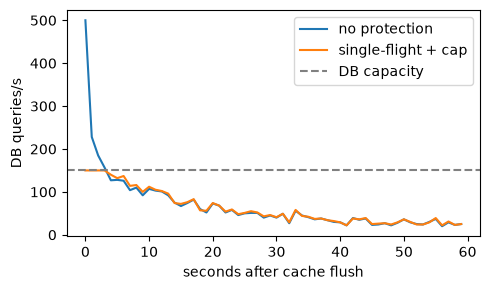

In [44]:
def cold_start(limit_concurrency, n_s=60, rps=500, n_keys=5000, db_capacity=150, seed=1):
    """Simulate the first minute after a cache flush. Returns peak DB load and errors."""
    rng = np.random.default_rng(seed)
    probs = zipf_probs(n_keys, 1.0)
    cached, peak, errors, timeline = set(), 0, 0, []
    for second in range(n_s):
        keys = rng.choice(n_keys, size=rps, p=probs)
        misses = [k for k in keys if k not in cached]
        unique = set(misses)
        db_load = len(unique) if limit_concurrency else len(misses)   # single-flight dedups
        if limit_concurrency:
            db_load = min(db_load, db_capacity)                          # shed the rest
        errors += max(0, db_load - db_capacity)
        loaded = list(unique)[:db_load] if limit_concurrency else list(unique)
        cached.update(loaded)
        peak = max(peak, db_load); timeline.append(db_load)
    return peak, errors, timeline

p1, e1, t1 = cold_start(False)
p2, e2, t2 = cold_start(True)
print(f"no protection     : peak DB queries/s = {p1}, overload errors = {e1}")
print(f"single-flight+cap : peak DB queries/s = {p2}, overload errors = {e2}")
plt.figure(figsize=(5, 3))
plt.plot(t1, label="no protection"); plt.plot(t2, label="single-flight + cap")
plt.axhline(150, ls="--", c="gray", label="DB capacity")
plt.xlabel("seconds after cache flush"); plt.ylabel("DB queries/s"); plt.legend(); plt.tight_layout(); plt.show()

### 5.5 Try it for real (optional)

Run a local server with Docker (any one of these):

```bash
# Redis 8 (Redis Open Source, includes JSON, search, vector sets)
docker run -d --name redis -p 127.0.0.1:6379:6379 redis:8

# Valkey
docker run -d --name valkey -p 127.0.0.1:6379:6379 valkey/valkey:9

# Talk to it
docker exec -it redis redis-cli PING
docker exec -it redis redis-cli SET hello world EX 60
docker exec -it redis redis-cli INFO stats | grep keyspace
```

Bind to `127.0.0.1` as shown so the port is not exposed on your network. Then `pip install redis` (redis-py) in your own environment. The next cell uses it **only if** both the package is installed and a server answers on `localhost:6379`; otherwise it prints a skip message.

Other free ways to practice: Redis Cloud and Upstash have free tiers; the AWS, Google Cloud and Azure free trials can create small ElastiCache / Memorystore / Azure Managed Redis instances (remember to delete them).

In [45]:
def redis_server_reachable(host="localhost", port=6379, timeout=0.2):
    try:
        with socket.create_connection((host, port), timeout=timeout):
            return True
    except OSError:
        return False

try:
    import redis                                   # redis-py, optional
except ImportError:
    redis = None

if redis is None or not redis_server_reachable():
    print("skipped: needs a Redis server on localhost:6379 and the redis-py package (pip install redis)")
else:
    rc = redis.Redis(host="localhost", port=6379, decode_responses=True, socket_timeout=0.5)
    rc.set("zt:demo:greeting", "hello from redis-py", ex=30)
    print("GET ->", rc.get("zt:demo:greeting"), "| TTL ->", rc.ttl("zt:demo:greeting"))
    pipe = rc.pipeline()
    for i in range(5):
        pipe.incr("zt:demo:counter")
    print("pipelined INCRs ->", pipe.execute())
    info = rc.info()
    print("server version:", info.get("redis_version"), "| used_memory_human:", info.get("used_memory_human"))
    rc.delete("zt:demo:greeting", "zt:demo:counter")

skipped: needs a Redis server on localhost:6379 and the redis-py package (pip install redis)


### 5.6 Certification and exam topic map

Caching and Redis-compatible services appear in several cloud exams. Exam names and objectives change; check the current exam guide.

| Exam area (named generally) | What from this notebook applies |
|---|---|
| AWS associate/professional architecture and developer exams | ElastiCache vs MemoryDB, cache-aside vs write-through, TTL, Multi-AZ replication, ElastiCache Serverless, security groups and in-transit encryption |
| AWS database specialty-style topics | choosing in-memory stores, durability (MemoryDB transaction log), cluster mode and sharding |
| Azure developer and architect exams | Azure Managed Redis, migration away from Azure Cache for Redis, caching patterns, Entra ID auth |
| Google Cloud architect / database engineer exams | Memorystore for Valkey vs Memorystore for Redis Cluster, HA and persistence options |
| Redis vendor certification | data types, persistence, replication, cluster, ACLs, Streams, Query Engine |
| System design interviews | sections 2 and 4 of this notebook, end to end |

## 6. Recap

| Topic | Key idea in one line |
|---|---|
| Why caches work | skewed (Zipf) traffic: a small hot set serves most requests |
| Hit-rate math | `avg = t_cache + (1-h) * t_src`; the miss rate is what you pay for |
| Where caches live | browser, CDN, proxy, in-process L1, Redis L2, DB buffer pool, provider prompt cache |
| HTTP headers | `private`/`no-store` for personal AI answers; `s-maxage` + `stale-while-revalidate` + `ETag` for public data |
| Patterns | cache-aside by default; write-behind for counters; refresh-ahead for expensive hot keys |
| TTL + jitter | every cache key gets a TTL; randomize it so keys do not expire together |
| Invalidation | delete-on-write, versioned keys, event-driven; always keep a TTL as a safety net |
| Stampede | single-flight + lock or XFetch; never let N requests recompute one key |
| Race condition | read-old / delete / write-old leaves stale data; use TTL, double delete, set-if-newer or CDC |
| Eviction | `allkeys-lru` for caches, `allkeys-lfu` for stable hot sets, `noeviction` for queues |
| Redis model | single-threaded command execution (each command atomic), I/O threads for networking |
| Persistence | RDB = snapshots, AOF = command log (`everysec`); caches can run without either |
| HA and scale | async replication, Sentinel for failover, Cluster with 16384 slots and `{hash tags}` |
| Performance | pipeline round trips; avoid big keys and `KEYS`; Lua/functions for atomic logic |
| AI use cases | LLM cache keyed by tenant+model+prompt hash+params; semantic cache; chat history with `LTRIM`+TTL; rate limits; quotas; Streams job queues with DLQ; pub/sub token fan-out; locks with fencing |
| Operations | Valkey on AWS/GCP, Azure Managed Redis on Azure (Azure Cache for Redis is retiring), Upstash for serverless, Redis Cloud; watch hit ratio, evictions, memory, fragmentation, slowlog |

## 7. Interview questions

**Q1. What is cache-aside, and what is its main weakness?**
The app reads the cache, and on a miss reads the database and writes the result into the cache. Weaknesses: the first request is slow, and data can be stale until the TTL ends or the key is deleted; with delete-on-write there is a race that can put an old value back.

**Q2. Your LLM cache has a 40% hit rate. How do you raise it safely?**
Normalize inputs before hashing (whitespace, casing where meaning does not change, sorted JSON), remove volatile parts from the prompt (timestamps, request ids), cache at the right level (retrieval results, embeddings, tool outputs, not only final answers), add a semantic cache with a strict threshold for FAQ-like traffic, and make the TTL longer with versioned invalidation. Never raise it by dropping the tenant or parameters from the key.

**Q3. What is a cache stampede and how do you prevent it?**
A hot key expires and many requests recompute it at once. Prevent with single-flight in each process, a Redis lock (`SET NX PX`) so one request recomputes while others serve stale data, probabilistic early expiry (XFetch), or background refresh of hot keys. Add TTL jitter so many keys do not expire together.

**Q4. Why is Redis fast if it is single-threaded?**
Data is in RAM, commands are simple in-memory operations, an event loop serves many connections without thread switching, and I/O threads handle the network work. The single thread also makes each command atomic. The cost: one slow command blocks everyone.

**Q5. How does Redis Cluster decide where a key lives? How do you run a multi-key operation?**
`CRC16(key) mod 16384` gives a slot; each primary owns slot ranges. Multi-key operations need all keys in one slot, which you get with hash tags: `{tenant:42}:a` and `{tenant:42}:b` hash only `tenant:42`.

**Q6. RDB or AOF?**
RDB is a periodic snapshot: compact, fast restart, but loses writes since the last snapshot. AOF logs every write: with `everysec` you lose about one second at most, but files are bigger. Use both for important data, and neither (or RDB only) for a pure cache.

**Q7. Design a rate limiter for an LLM API with many API servers.**
Keep counters in Redis, keyed per API key/tenant and model. Use a token bucket (bursts allowed) or sliding window counter (cheap, accurate enough), implemented as a Lua script or function so check-and-update is atomic. Limit both requests/min and tokens/min, reserve estimated tokens before the call and settle after. Return `429` with a `Retry-After` header.

**Q8. Lists or Streams for a job queue?**
Plain lists lose jobs if a worker crashes after popping. Streams with consumer groups keep each delivered entry pending until `XACK`, let other workers reclaim stuck entries with `XAUTOCLAIM`, track delivery counts for dead-lettering, and allow several consumer groups. Either way, jobs must be idempotent because delivery is at-least-once.

**Q9. Is a Redis lock safe for protecting a payment?**
Not by itself. A `SET NX PX` lock can expire while the holder is paused, and async replication can lose the lock on failover. For correctness use fencing tokens checked by the storage layer, or a consensus-backed lock (etcd, ZooKeeper) or database transaction. Use Redis locks for efficiency (avoiding duplicate work).

**Q10. Redis vs Valkey: does it matter for my application code?**
Usually not: same protocol, same core commands, same clients (redis-py works with both). Differences are licence, governance, which cloud offers which, and newer features (Redis 8's vector sets and Query Engine vs Valkey's own modules and cluster features). Pin your client and test the commands you use.

## 8. Further reading

**Official documentation**
- Redis docs, data types and commands: https://redis.io/docs/latest/develop/data-types/
- What's new in Redis 8.0 (vector sets, built-in modules, new hash commands): https://redis.io/docs/latest/develop/whats-new/8-0/
- What's new in Redis 8.4 (FT.HYBRID, DELEX, CLUSTER MIGRATION): https://redis.io/docs/latest/develop/whats-new/8-4/
- Redis 8 GA announcement and licensing: https://redis.io/blog/redis-8-ga/
- Redis persistence (RDB, AOF): https://redis.io/docs/latest/operate/oss_and_stack/management/persistence/
- Redis Cluster specification (hash slots, CRC16, hash tags): https://redis.io/docs/latest/operate/oss_and_stack/reference/cluster-spec/
- Key eviction policies: https://redis.io/docs/latest/develop/reference/eviction/
- Client-side caching: https://redis.io/docs/latest/develop/reference/client-side-caching/
- Distributed locks with Redis: https://redis.io/docs/latest/develop/use/patterns/distributed-locks/
- Redis LangCache: https://redis.io/docs/latest/develop/ai/langcache/
- Valkey project history: https://valkey.io/topics/history/ and Valkey 9.0: https://valkey.io/download/9.0/
- Amazon ElastiCache vector search announcement (Oct 2025): https://aws.amazon.com/about-aws/whats-new/2025/10/amazon-elasticache-vector-search
- Amazon MemoryDB for Valkey announcement: https://aws.amazon.com/about-aws/whats-new/2024/10/amazon-memorydb-valkey
- Google Cloud Memorystore: https://cloud.google.com/memorystore
- Azure Cache for Redis retirement FAQ: https://learn.microsoft.com/en-us/azure/azure-cache-for-redis/retirement-faq
- Upstash Redis docs: https://upstash.com/docs/redis

**Papers and essays**
- A. Vattani, F. Chierichetti, K. Lowenstein, "Optimal Probabilistic Cache Stampede Prevention", VLDB 2015 (XFetch).
- M. Kleppmann, "How to do distributed locking" (2016), and antirez, "Is Redlock safe?" (2016).
- RFC 9111 (HTTP Caching) and RFC 5861 (stale-while-revalidate, stale-if-error).
- L. Breslau et al., "Web Caching and Zipf-like Distributions: Evidence and Implications", INFOCOM 1999.

**In this repo**
- [System Design Fundamentals](../23_Software_Engineering/09_system_design_fundamentals.ipynb) · [NoSQL Databases](02_nosql/01_nosql_databases.ipynb) · [NoSQL and Data Stores](../22_ML_System_Design/04_nosql_and_data_stores.ipynb) · [Distributed Systems Patterns](../22_ML_System_Design/10_distributed_systems_and_architecture_patterns.ipynb) · [Designing for 100 Million Users](../22_ML_System_Design/12_designing_for_100_million_users.ipynb) · [LLM Caching](../08_LLM/23_llm_caching_kv_cache_prompt_semantic_cag.ipynb) · [Indexing Patterns](09_indexing_patterns_database_and_vector_side_by_side.ipynb) · [Message Queues](../16_Deployment/message_queues/01_message_queues.ipynb)